# PlantaIa — Tarea 2: clasificador en la ESP32

Este notebook implementa y compara los clasificadores de la Tarea 2 y elige el que va a la placa. El contrato (features, target, protocolo, criterio de selección) es [`docs/ENTREGA2.md`](../docs/ENTREGA2.md); el código compartido está en `ml/plantaia_ml/` y el modelo exportado en `firmware/lib/plantaia_ml/modelo_plantaia.h`.

**Qué datos se usan.** Hay una sola maceta, `maceta-01`. Sus mediciones reales (12/09 al 21/10) tienen huecos de hasta 15 días y muy pocos episodios de etiqueta utilizables; el notebook 02 mostró que con eso un modelo no generaliza (5 % de exactitud balanceada por episodio). Los huecos se completaron **localmente** con un simulador calibrado con lo medido (`data/sintetico/`, fuera del repo; ver su README y `docs/entrega2/AUDITORIA_DATOS.md`). Cada fila lleva la marca `fuente`:

* `real`: lo midió la placa;
* `simulada_relleno`: la generó el simulador.

**Restricción de diseño (decisión de producto).** El semáforo de la placa no puede depender sólo de la sonda de suelo: todo candidato con selección de features usa `suelo_mv` **y al menos una variable ambiental** (T, HR, VPD, luz o luz media). Los baselines de umbral sobre `suelo_mv` quedan como referencia. Además, **después de ver los resultados** se agregaron dos condiciones de producto: la ambiental tiene que cambiar la clase de ≥ 1 % de las filas reales (§5.5), y el modelo no puede perder la marchita real (§5.6: recall de marchita real ≥ 0,9 y el ep. 12 bien). La §5.7 explica la restricción, compara con el modelo sólo-suelo anterior (`rf-f0-c42286`) y verifica con las filas medidas que la ambiental cambia predicciones.

La marca sirve para lo más importante de este notebook: **no medir el modelo sólo contra datos que generó el propio simulador**. La §6 evalúa sobre las filas reales.

Para no volcar el relleno al repo, el notebook muestra sólo agregados y figuras de las filas simuladas, nunca filas sueltas. Para re-ejecutarlo hace falta el complemento local; sin él, `serie_maceta01()` devuelve sólo lo real.

**Re-ejecución.** El código no tiene números fijos: si se reemplaza el relleno, se vuelve a correr tal cual (`jupyter nbconvert --to notebook --execute --inplace notebooks/03_modelos.ipynb`). La §5.5 avisa si la selección ya no coincide con `CONFIG_FINAL` o si el header exportado quedó viejo, y la §7 reescribe `docs/entrega2/tablas_03_modelos.md` con todas las tablas. Los comentarios en texto describen la ejecución commiteada: la final, con el relleno **v2** (la fecha del relleno se imprime abajo).

In [1]:
import sys
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.patches import Patch
from scipy import stats
from sklearn.base import clone
from sklearn.metrics import (balanced_accuracy_score, confusion_matrix, f1_score,
                             recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedGroupKFold, StratifiedKFold
from sklearn.tree import export_text, plot_tree

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "ml" / "plantaia_ml").is_dir())
sys.path.insert(0, str(RAIZ / "ml"))

from plantaia_ml import CLASES, FIGURAS
from plantaia_ml import dataset as _dataset
from plantaia_ml.dataset import serie_maceta01
from plantaia_ml.datos_reales import EPISODIOS_DUDOSOS
from plantaia_ml.exportar_c import RUTA_MODELO, bytes_parametros_c, version_modelo
from plantaia_ml.features import FEATURES
from plantaia_ml.modelos import (AMBIENTALES, COLUMNAS_NO_FEATURES, CONFIG_FINAL, EP_MARCHITA_OCTUBRE,
                                 MIN_ACIERTO_EP12, MIN_CAMBIO_PCT, MIN_RECALL_MARCHITA,
                                 configuraciones_seguridad, K_EXTERNO,
                                 K_INTERNO, SUBCONJUNTOS, baselines, busqueda, candidatos,
                                 costo_esp32, cumple_restriccion, matriz_X, modelo_final,
                                 nombre_subconjunto, particion_externa, particion_interna)
from plantaia_ml.modelos import UmbralesOrdenados

warnings.filterwarnings("ignore", category=FutureWarning)
from sklearn.exceptions import FitFailedWarning
# §6.1: con pocos episodios reales algunos folds internos quedan con una sola clase; esas
# configuraciones se puntúan NaN (se avisa en la celda) en vez de cortar la ejecución.
warnings.filterwarnings("ignore", category=FitFailedWarning)
warnings.filterwarnings("ignore", category=UserWarning)           # f1 con clases ausentes en un fold
warnings.filterwarnings("ignore", message=".*ill-defined.*")
warnings.filterwarnings("ignore", message=".*Stochastic Optimizer.*")
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
sns.set_theme(style="whitegrid", context="notebook")
FIGURAS.mkdir(parents=True, exist_ok=True)
SALIDA_TABLAS = RAIZ / "docs" / "entrega2" / "tablas_03_modelos.md"

# De dónde sale el relleno simulado (para saber con cuál se ejecutó el notebook). No hay
# números fijos en el código: si se reemplaza el relleno, se re-ejecuta tal cual.
_rutas_relleno = [getattr(_dataset, n) for n in ("RUTA_PAYLOADS", "RUTA_COMPLEMENTO") if hasattr(_dataset, n)]
_ruta = next((r for r in _rutas_relleno if r.exists()), None)
RELLENO_INFO = ("sin relleno local (sólo reales)" if _ruta is None else
                f"{_ruta.relative_to(RAIZ)} ({pd.Timestamp(_ruta.stat().st_mtime, unit='s', tz='UTC'):%Y-%m-%d %H:%M} UTC)")
print("relleno:", RELLENO_INFO)

COLORES = {"saludable": "#4c9f70", "estresada": "#e6a23c", "marchita": "#c84b4b"}
CODIGOS = [1, 2, 3]
FUENTES = {"real": "real (placa)", "simulada_relleno": "relleno simulado"}


def guardar(fig, nombre):
    fig.savefig(FIGURAS / nombre, dpi=150, bbox_inches="tight")
    print(f"figura: docs/entrega2/fig/{nombre}")

relleno: data/sintetico/payloads_relleno.jsonl (2026-10-21 23:58 UTC)


## 1. Datos

`serie_maceta01()` arma la serie completa de la maceta a 5 min: remuestrea el dato real (que quedó a 30 s) con la mediana por bin, cruza cada fila con su episodio de `data/episodios.csv` (o de `episodios_relleno.csv` en el relleno), calcula las features como las calcularía la placa y recién después filtra: fuera los primeros 60 min tras cada arranque (transitorio de la sonda), la sonda saturada, las filas sin vector completo y las que no caen en ningún episodio.

### Qué entra al modelo y qué no (*drop* de etiquetas)

La tabla de modelado trae, además de las 7 features, la etiqueta y **de dónde salió**: la clase en texto, `etiqueta_origen` (`manual`, `propagada`, `corregida`), la marca `dudoso`, el `episodio_id`, la `fuente` (real o simulada), las marcas de calidad (`warmup`, `valido`, `post_boot`, …) y la hora. Ninguna de esas columnas existe en la placa, y varias están **correlacionadas con la etiqueta por cómo se armó el dato** (por ejemplo, todas las filas de un episodio dudoso son de la misma clase, y las simuladas tienen otra proporción de clases que las reales). Si entraran a `X`, el modelo podría aprender la procedencia de la etiqueta en vez de la condición de la planta.

Por eso `X` se arma **descartando explícitamente** esas columnas, y un `assert` exige que lo que queda sea exactamente el contrato §4 (las 7 features, en orden). `y` es `clase_codigo`; `episodio_id` se usa **sólo** como grupo de la partición y `fuente`/`dudoso` **sólo** para evaluar sobre lo medido. El exportador usa el mismo resguardo (`modelos.matriz_X`).


In [2]:
df = serie_maceta01()

# X: se descartan EXPLÍCITAMENTE todas las columnas que no son features (etiqueta y su procedencia,
# identificación, tiempo, marcas de calidad) antes de cualquier fit. Ver la explicación arriba.
METADATOS = ["ts", "dispositivo", "boot_id", "tramo",                 # identificación y tiempo
             "clase", "clase_codigo", "etiqueta_origen", "dudoso",    # la etiqueta y de dónde salió
             "episodio_id", "fuente",                                 # grupo de la partición / real vs simulado
             "warmup", "valido", "post_boot", "suelo_saturado",       # marcas de calidad
             "errores", "marcas", "temp_ntc_c"]                       # termistor: fuera del contrato §4
# Columnas de procedencia que la tabla hoy no trae pero que nunca pueden entrar a X si aparecen.
METADATOS_SI_APARECEN = ["etiqueta", "origen", "nota", "flags", "muestra_id", "ts_iso", "ts_unix"]
assert set(METADATOS + METADATOS_SI_APARECEN) == set(COLUMNAS_NO_FEATURES), "misma lista que modelos.matriz_X"
X_df = df.drop(columns=METADATOS + [c for c in METADATOS_SI_APARECEN if c in df.columns])
assert sorted(X_df.columns) == sorted(FEATURES), f"X tiene columnas fuera del contrato §4: {list(X_df.columns)}"
X_df = X_df[FEATURES]
assert list(X_df.columns) == FEATURES                    # exactamente el contrato §4, en su orden
X = X_df.to_numpy(np.float32)      # float32, como la placa y como sklearn recorre los árboles
assert np.array_equal(X, matriz_X(df)), "el resguardo de modelos.py (lo usa el exportador) da lo mismo"
y = df.clase_codigo.to_numpy(int)                 # target: código del firmware 1..3
g = df.episodio_id.to_numpy(int)                  # SÓLO como grupo de la partición por episodio
es_real = (df.fuente == "real").to_numpy()        # SÓLO para evaluar sobre lo medido
dudoso = df.dudoso.to_numpy(bool)                 # SÓLO para reportar con y sin dudosos
print("X:", X.shape, "columnas:", list(X_df.columns))

print(f"filas: {len(df):,} · episodios: {df.episodio_id.nunique()} · "
      f"desde {df.ts.min():%d/%m %H:%M} hasta {df.ts.max():%d/%m %H:%M} UTC")
print(f"filas reales: {es_real.sum():,} ({es_real.mean():.1%}) · "
      f"episodios con al menos una fila real: {df[es_real].episodio_id.nunique()}")
mixtos = df.groupby("episodio_id").fuente.nunique()
print(f"episodios con filas de las dos fuentes (huecos chicos rellenados dentro de un episodio real): "
      f"{sorted(mixtos[mixtos > 1].index.tolist())}")

def conteos(d):
    return pd.Series({"filas": len(d), "episodios": d.episodio_id.nunique()})


filas_conteo = {}
for c in CLASES + ["total"]:
    dc = df if c == "total" else df[df.clase == c]
    fila = {}
    for f in ["real", "simulada_relleno"]:
        for k, v in conteos(dc[dc.fuente == f]).items():
            fila[(FUENTES[f], k)] = v
    for k, v in conteos(dc).items():
        fila[("serie completa", k)] = v
    filas_conteo[c] = fila
tabla_conteo = pd.DataFrame(filas_conteo).T
display(tabla_conteo)
print("proporción de filas por clase:", (df.clase.value_counts(normalize=True).reindex(CLASES)
                                         .round(3).to_dict()))

X: (11051, 7) columnas: ['suelo_mv', 'suelo_delta_1h', 'temp_c', 'hum_aire_pct', 'vpd_kpa', 'luz_mv', 'luz_media_1h']
filas: 11,051 · episodios: 47 · desde 13/09 00:55 hasta 21/10 21:20 UTC
filas reales: 1,321 (12.0%) · episodios con al menos una fila real: 11
episodios con filas de las dos fuentes (huecos chicos rellenados dentro de un episodio real): [1, 3, 6, 8, 9, 10, 12, 13, 14]


real (placa)           relleno simulado           serie completa          
                 filas episodios            filas episodios          filas episodios
saludable          423         3             5178        10           5601        12
estresada          576         5             2112        20           2688        20
marchita           322         3             2440        15           2762        15
total             1321        11             9730        45          11051        47

proporción de filas por clase: {'saludable': 0.507, 'estresada': 0.243, 'marchita': 0.25}


Las filas son muchas pero **no son independientes**: dentro de un episodio todas comparten etiqueta y las contiguas están a 5 min. El N que importa para todo lo que sigue es el de **episodios**. Los episodios reales utilizables son pocos y casi todos de octubre.

Tabla de los episodios reales (agregados por episodio; los dudosos son los de `EPISODIOS_DUDOSOS`, con el motivo en `data/episodios.csv`):

In [3]:
reales_ep = (df[es_real].groupby("episodio_id")
             .agg(clase=("clase", "first"), origen=("etiqueta_origen", "first"),
                  dudoso=("dudoso", "first"), filas=("ts", "size"),
                  desde=("ts", "min"), suelo_mv_mediana=("suelo_mv", "median"),
                  temp_c_mediana=("temp_c", "median"), luz_mv_mediana=("luz_mv", "median")))
reales_ep["desde"] = reales_ep.desde.dt.strftime("%d/%m %H:%M")
display(reales_ep)
for k, v in EPISODIOS_DUDOSOS.items():
    print(f"dudoso {k}: {v}")

,clase,origen,dudoso,filas,desde,suelo_mv_mediana,temp_c_mediana,luz_mv_mediana
episodio_id,,,,,,,,
1,marchita,corregida,False,131,13/09 00:55,"2,832.000",8.500,189.000
3,estresada,manual,False,23,15/09 13:35,"2,769.500",34.200,"2,037.500"
6,estresada,manual,False,69,16/09 17:55,"2,050.000",14.400,"2,782.000"
8,marchita,manual,True,105,01/10 01:40,"1,512.000",20.600,142.000
9,estresada,manual,True,51,01/10 10:55,"1,454.000",19.000,"2,298.500"
10,saludable,manual,False,137,02/10 01:55,"1,504.000",18.600,"1,978.000"
11,saludable,propagada,True,27,19/10 00:35,"1,785.500",20.200,142.000
12,marchita,manual,False,86,19/10 02:50,"1,758.000",20.200,142.000
13,estresada,manual,False,136,19/10 10:20,"1,929.750",19.400,"1,666.750"


dudoso 8: marchita con el sustrato igual que saludable (~1550 mV), nocturna
dudoso 9: estresada con el sustrato en ~1454 mV, el rango de los saludable de octubre
dudoso 11: propagada de Preferences 16 días después; contradicha por la observación siguiente
dudoso 14: estresada propagada ~25 h después de un riego, sin nadie que la confirme


figura: docs/entrega2/fig/serie_maceta01_modelado.png


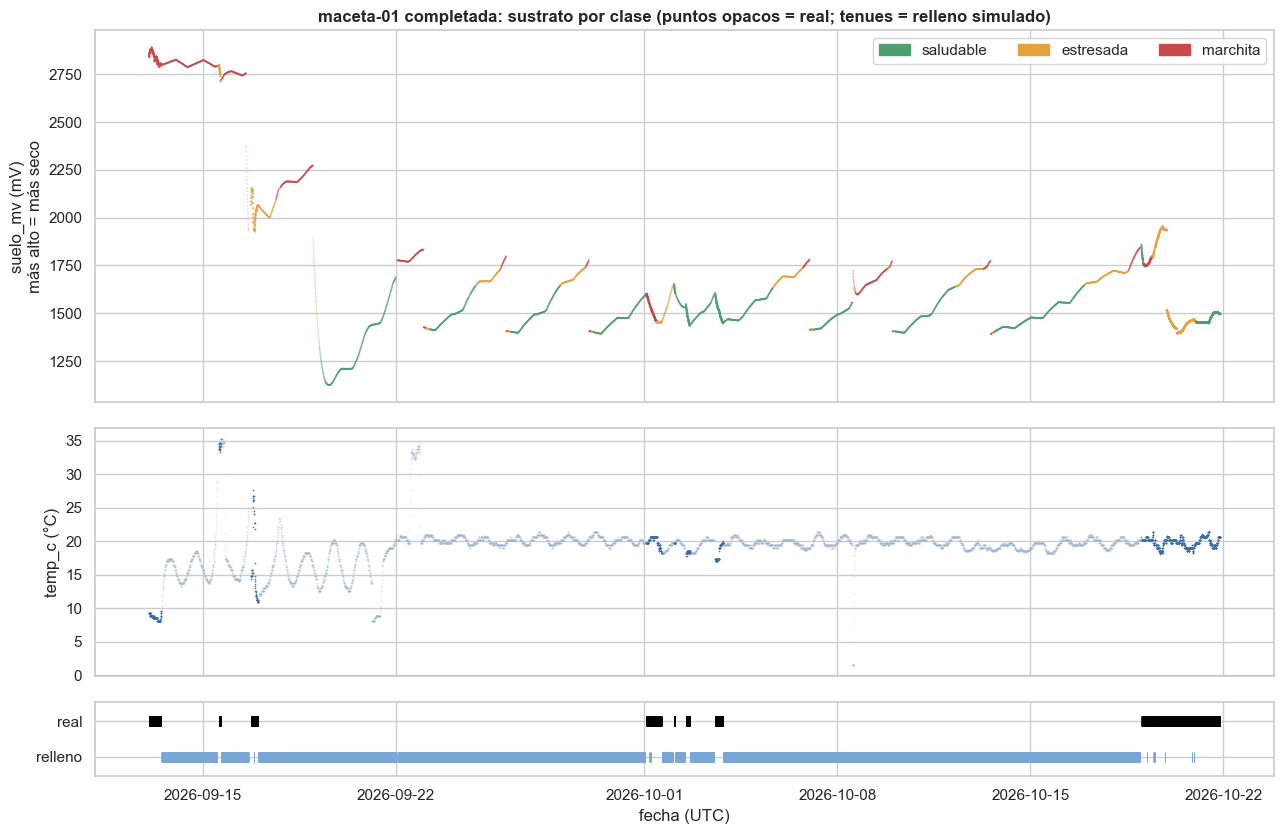

In [4]:
fig, axes = plt.subplots(3, 1, figsize=(13, 8.5), sharex=True,
                         gridspec_kw={"height_ratios": [3, 2, 0.6]})
ax = axes[0]
for f, marca, alfa, tam in [("simulada_relleno", "o", 0.25, 1.5), ("real", "o", 0.9, 2.5)]:
    d = df[df.fuente == f]
    ax.scatter(d.ts, d.suelo_mv, s=tam, c=d.clase.map(COLORES), alpha=alfa, lw=0, rasterized=True)
ax.set_ylabel("suelo_mv (mV)\nmás alto = más seco")
ax.set_title("maceta-01 completada: sustrato por clase (puntos opacos = real; tenues = relleno simulado)",
             fontweight="bold")
ax.legend(handles=[Patch(color=COLORES[c], label=c) for c in CLASES], ncol=3, loc="upper right")
ax = axes[1]
for f, alfa in [("simulada_relleno", 0.25), ("real", 0.9)]:
    d = df[df.fuente == f]
    ax.scatter(d.ts, d.temp_c, s=1.5, c="#3a6ea5" if f == "real" else "#9bb7d4", alpha=alfa, lw=0,
               rasterized=True)
ax.set_ylabel("temp_c (°C)")
ax = axes[2]
for f, y0, col in [("real", 0.55, "black"), ("simulada_relleno", 0.0, "#7aa6d6")]:
    d = df[df.fuente == f]
    ax.scatter(d.ts, np.full(len(d), y0 + 0.2), marker="|", s=60, c=col, lw=0.6, rasterized=True)
ax.set_yticks([0.2, 0.75], ["relleno", "real"])
ax.set_ylim(-0.1, 1.05)
ax.set_xlabel("fecha (UTC)")
fig.tight_layout()
guardar(fig, "serie_maceta01_modelado.png")
plt.show()

**Lo que se ve** (ejecución con el relleno v2).

- **Dónde hay dato real.** La serie real ocupa pocas ventanas: 12–17/09, 1–3/10 y 18–21/10. El relleno cubre el resto con ciclos de secado → riego. Lo real es el 12 % de las filas y 11 de los 47 episodios.
- **La escala de la sonda se corre entre meses.** En septiembre la `marchita` real marcaba ~2830 mV. En octubre la marchita observada con el botón (ep. 12) está en ~1758 mV, por debajo de la mediana de la `estresada` del día siguiente (ep. 13, ~1930 mV).
- **Cómo se calibró el relleno v2.** Para octubre usa una curva anclada en lo medido (marchita desde ~1745 mV, lo más seco ~1960 mV). Ninguna fila simulada de octubre pasa del máximo real del mes.
- **Episodios perdidos.** El corte de 60 min tras cada arranque elimina enteros algunos episodios reales cortos de septiembre (`AUDITORIA_DATOS.md`, H7).

## 2. Preparación, features y target

**Features** (contrato §4, mismo código en Python y en C, con test de paridad): se calculan cada 5 min con la muestra actual y un buffer de 13 muestras (1 h). La placa arma siempre los 7 en este orden; si el modelo usa menos, el exportador remapea índices.

| idx | feature | qué es |
|---|---|---|
| 0 | `suelo_mv` | sonda resistiva, mediana de 9 (mV; más alto = más seco) |
| 1 | `suelo_delta_1h` | `suelo_mv(t) − suelo_mv(t−1 h)`; 0 en warm-up |
| 2 | `temp_c` | DHT11 (último válido si falla) |
| 3 | `hum_aire_pct` | DHT11 |
| 4 | `vpd_kpa` | déficit de presión de vapor (Tetens) con 2 y 3 |
| 5 | `luz_mv` | LDR, mediana de 9 |
| 6 | `luz_media_1h` | media de `luz_mv` en la última hora |

**Fuera a propósito**: la hora del día (en el dato real está confundida con el horario del observador, §6.4), `luz_pct`/`suelo_pct` (sin calibrar) y el termistor (su conversión en el firmware 1.1.0 está invertida).

**Target**: códigos del firmware 1 `saludable`, 2 `estresada`, 3 `marchita`. `sin_etiquetar` (0) no es clase: las filas sin episodio ya quedaron afuera en el filtrado. Las filas de warm-up (primera hora de cada tramo) **se quedan**: la placa también infiere en esa hora, con `suelo_delta_1h = 0`.

In [5]:
assert set(np.unique(y)) == {1, 2, 3}, "el target tiene que ser exactamente 1..3"
assert not df.clase.isin(["sin_etiquetar"]).any() and df.episodio_id.notna().all()
assert np.isfinite(X).all(), "no puede haber NaN en el vector (la placa no infiere sin vector completo)"
print(f"filas en warm-up (suelo_delta_1h = 0): {df.warmup.sum():,} ({df.warmup.mean():.1%})")

resumen = (df.groupby(["clase", "fuente"])[FEATURES].median().unstack("fuente")
           .reindex(CLASES).T)
resumen.index = [f"{f} · {FUENTES[s]}" for f, s in resumen.index]
print("Mediana de cada feature por clase y fuente:")
display(resumen)

filas en warm-up (suelo_delta_1h = 0): 144 (1.3%)
Mediana de cada feature por clase y fuente:


clase,saludable,estresada,marchita
suelo_mv · real (placa),"1,480.000","1,462.750","1,769.500"
suelo_mv · relleno simulado,"1,476.500","1,690.000","2,121.500"
suelo_delta_1h · real (placa),-2.000,2.000,-10.250
suelo_delta_1h · relleno simulado,4.500,3.500,3.000
temp_c · real (placa),19.800,19.400,20.200
temp_c · relleno simulado,19.800,19.800,19.000
hum_aire_pct · real (placa),48.000,46.000,50.000
hum_aire_pct · relleno simulado,47.000,47.000,47.500
vpd_kpa · real (placa),1.201,1.226,1.184
vpd_kpa · relleno simulado,1.224,1.217,1.121


**Lectura de las medianas.**

- **Relleno v2.** `suelo_mv` ordena las clases (saludable < estresada < marchita) y la luz ya no está invertida: las tres clases tienen luz parecida.
- **Real.** La marchita es nocturna (142 mV = oscuridad del LDR) y la `estresada` tiene el sustrato de una saludable, por los episodios dudosos 9 y 14.
- **Delta.** `suelo_delta_1h` sigue distinto entre fuentes: lo real deriva hacia abajo por los transitorios post-arranque, que el relleno no tiene.

En T, HR y VPD las tres clases tienen medianas casi iguales, en lo real y en el relleno: la información ambiental, si existe, está en las colas (radiador, frío), no en el centro. La luz real separa marchita (noche) del resto, pero eso es la hora del observador (§6.5).

## 3. Protocolo de evaluación

* **Partición externa por episodio**: `StratifiedGroupKFold` con k = 5 y `episodio_id` como grupo. Un episodio entero cae en train o en test, nunca partido. Es `GroupKFold` repartiendo los episodios para que cada fold tenga las tres clases (con `GroupKFold` a secas un fold se queda sin `marchita` y el recall de esa clase no se puede medir ahí).
* **Búsqueda de hiperparámetros anidada**: dentro de cada fold externo, `GridSearchCV` con otra partición por episodio (k = 3) sobre el train, maximizando F1 macro. El subconjunto de features es un hiperparámetro más, **restringido** a `suelo_mv` + al menos una ambiental (§5.6): suelo + cada ambiental, suelo + delta + cada ambiental, suelo + cada par de ambientales, `sin luz` y `todas` (22 subconjuntos). El fold externo no participa de la elección.
* **Métricas por fold** y luego media ± desvío: exactitud balanceada (el azar con 3 clases es 0,33), F1 macro, recall de `marchita` (el error caro es no avisar) y ROC-AUC OvR cuando el modelo da probabilidades. Las matrices de confusión suman las predicciones fuera de fold de los 5 folds.

### ¿Por qué no un split aleatorio?

Las filas contiguas comparten etiqueta y son casi iguales. Con un split aleatorio, cada fila de test tiene a su vecina de 5 min en train: el modelo puede "reconocer el episodio" en vez de la condición de la planta. Mismo modelo y mismos datos, dos particiones:

In [6]:
from sklearn.ensemble import RandomForestClassifier


def bosque_todas():
    # Random Forest con las 7 features, sin búsqueda: el más capaz de memorizar episodios.
    return candidatos()["Random Forest"][0].set_params(sel__columnas=SUBCONJUNTOS["todas"],
                                                       clf__max_depth=8, clf__min_samples_leaf=20)


def comparar_particiones(est, X_, y_, g_):
    out = {}
    for nombre, cv, grupos in [("aleatoria (filas mezcladas)",
                                StratifiedKFold(K_EXTERNO, shuffle=True, random_state=0), None),
                               ("por episodio", particion_externa(), g_)]:
        ba = []
        for tr, te in cv.split(X_, y_, grupos):
            p = clone(est).fit(X_[tr], y_[tr]).predict(X_[te])
            ba.append(balanced_accuracy_score(y_[te], p))
        out[nombre] = f"{np.mean(ba):.3f} ± {np.std(ba):.3f}"
    return out


fuga = pd.DataFrame({
    "serie completa · RF 7 features": comparar_particiones(bosque_todas(), X, y, g),
    "sólo reales · RF 7 features": comparar_particiones(bosque_todas(), X[es_real], y[es_real], g[es_real]),
}).T
fuga.columns.name = "exactitud balanceada (5 folds)"
display(fuga)

exactitud balanceada (5 folds),aleatoria (filas mezcladas),por episodio
serie completa · RF 7 features,0.887 ± 0.009,0.681 ± 0.133
sólo reales · RF 7 features,0.947 ± 0.012,0.291 ± 0.356


**La fuga es grande.** El mismo Random Forest pasa de 0,887 de exactitud balanceada con filas mezcladas a 0,681 por episodio en la serie completa. En los reales solos pasa de 0,947 a 0,291, por debajo del azar y con un desvío enorme: es el hallazgo del notebook 02, que se sostiene con los episodios nuevos.

Todo lo que sigue usa partición por episodio. El N efectivo es el número de episodios, no el de filas.

## 4. Baselines y candidatos

**Baselines obligatorios** (sin búsqueda; se ajustan en el train de cada fold):

* *Clase mayoritaria*: siempre `saludable`.
* *Umbral único sobre `suelo_mv`*: un tocón (árbol de profundidad 1). Con un solo corte predice como mucho dos clases: es el baseline literal del plan.
* *Dos umbrales sobre `suelo_mv`*: la regla ordinal que pondría alguien mirando el histograma (`suelo ≤ t1` saludable, `≤ t2` estresada, si no marchita), con t1 y t2 elegidos en el train por F1 macro. Es el rival honesto: cualquier modelo que no le gane no justifica su complejidad.

**Candidatos** (§5.2, grillas en `ml/plantaia_ml/modelos.py`): regresión logística, árbol de decisión (prof. ≤ 8), Random Forest (30 árboles, prof. ≤ 8), Naive Bayes gaussiano, k-NN, SVM RBF y MLP chico. `class_weight="balanced"` donde existe (hay ~2 filas `saludable` por cada `marchita`). Todos eligen su subconjunto dentro del espacio restringido (suelo + ≥ 1 ambiental); los baselines usan sólo `suelo_mv` y no son elegibles.

In [7]:
def recall_marchita(y_, p_):
    return recall_score(y_, p_, labels=[3], average="macro", zero_division=0)


def metricas(y_, p_, proba_=None):
    m = {"exactitud_bal": balanced_accuracy_score(y_, p_),
         "f1_macro": f1_score(y_, p_, labels=CODIGOS, average="macro", zero_division=0),
         "recall_marchita": recall_marchita(y_, p_),
         "roc_auc_ovr": np.nan}
    if proba_ is not None and len(np.unique(y_)) == 3 and np.isfinite(proba_).all():
        m["roc_auc_ovr"] = roc_auc_score(y_, proba_, multi_class="ovr", average="macro", labels=CODIGOS)
    return m


def proba_3(modelo, X_):
    # predict_proba con las columnas 1..3 aunque el train no haya visto alguna clase.
    try:
        p = modelo.predict_proba(X_)
    except AttributeError:
        return None
    out = np.zeros((len(X_), 3))
    for j, c in enumerate(modelo.classes_):
        out[:, CODIGOS.index(int(c))] = p[:, j]
    return out


def evaluar(est, grilla, X_, y_, g_, cv=None, n_jobs=-1, tolerante=False):
    # Evaluación por episodio; con grilla, búsqueda anidada. Devuelve métricas por fold y predicciones fuera de fold.
    cv = cv or particion_externa()
    folds, elegidos = [], []
    oof = np.zeros(len(y_), int)
    oof_p = np.full((len(y_), 3), np.nan)
    for tr, te in cv.split(X_, y_, g_):
        if grilla:
            b = busqueda(est, grilla, n_jobs=n_jobs)
            if tolerante:   # con pocos episodios un fold interno puede quedar con una sola clase
                b.set_params(error_score=np.nan)
            b = b.fit(X_[tr], y_[tr], groups=g_[tr])
            modelo = b.best_estimator_
            elegidos.append(b.best_params_)
        else:
            modelo = clone(est).fit(X_[tr], y_[tr])
            elegidos.append({})
        oof[te] = modelo.predict(X_[te])
        p = proba_3(modelo, X_[te])
        if p is not None:
            oof_p[te] = p
        folds.append(metricas(y_[te], oof[te], p))
    return {"folds": pd.DataFrame(folds), "oof": oof, "oof_p": oof_p, "elegidos": elegidos}


def resumir(res):
    f = res["folds"]
    return {f"{k} (media)": f[k].mean() for k in f} | {f"{k} (desvío)": f[k].std(ddof=0) for k in f}


MODELOS = {**baselines(), **candidatos()}
ES_BASELINE = {n: n in baselines() for n in MODELOS}
resultados, tiempos = {}, {}
for nombre, (est, grilla) in MODELOS.items():
    t0 = time.perf_counter()
    resultados[nombre] = evaluar(est, grilla, X, y, g)
    tiempos[nombre] = time.perf_counter() - t0
    print(f"{nombre:<26} {tiempos[nombre]:6.1f} s")

Clase mayoritaria             0.0 s
Umbral único (suelo_mv)       0.0 s


Dos umbrales (suelo_mv)       0.3 s


Regresión logística           4.7 s


Árbol de decisión             2.6 s


Random Forest                11.9 s


Naive Bayes                   0.3 s


k-NN                          7.9 s


SVM RBF                      69.0 s


MLP                          37.8 s


In [8]:
METRICAS = ["exactitud_bal", "f1_macro", "recall_marchita", "roc_auc_ovr"]


def tabla_metricas(res_por_modelo):
    filas = {}
    for n, r in res_por_modelo.items():
        f = r["folds"]
        filas[n] = {m: f"{f[m].mean():.3f} ± {f[m].std(ddof=0):.3f}" if f[m].notna().all() else "n/d"
                    for m in METRICAS}
    return pd.DataFrame(filas).T


print(f"Serie completa · {df.episodio_id.nunique()} episodios · StratifiedGroupKFold k={K_EXTERNO} "
      f"(media ± desvío entre folds)")
tabla_cv = tabla_metricas(resultados)
display(tabla_cv)

resumen_cv = pd.DataFrame({n: resumir(r) for n, r in resultados.items()}).T

Serie completa · 47 episodios · StratifiedGroupKFold k=5 (media ± desvío entre folds)


,exactitud_bal,f1_macro,recall_marchita,roc_auc_ovr
Clase mayoritaria,0.333 ± 0.000,0.232 ± 0.036,0.000 ± 0.000,0.500 ± 0.000
Umbral único (suelo_mv),0.601 ± 0.060,0.523 ± 0.058,0.823 ± 0.183,0.760 ± 0.089
Dos umbrales (suelo_mv),0.751 ± 0.118,0.749 ± 0.123,0.811 ± 0.184,n/d
Regresión logística,0.614 ± 0.142,0.606 ± 0.157,0.422 ± 0.266,0.834 ± 0.065
Árbol de decisión,0.728 ± 0.136,0.706 ± 0.183,0.775 ± 0.171,0.817 ± 0.090
Random Forest,0.688 ± 0.123,0.664 ± 0.150,0.797 ± 0.181,0.820 ± 0.103
Naive Bayes,0.556 ± 0.110,0.534 ± 0.109,0.415 ± 0.282,0.771 ± 0.123
k-NN,0.671 ± 0.124,0.652 ± 0.144,0.687 ± 0.261,0.821 ± 0.085
SVM RBF,0.600 ± 0.163,0.601 ± 0.165,0.487 ± 0.233,n/d
MLP,0.625 ± 0.176,0.628 ± 0.174,0.457 ± 0.244,0.793 ± 0.091


**Hiperparámetros que eligió la búsqueda interna en cada fold externo.** Si cambian mucho de un fold a otro, la elección es inestable (otra señal de pocos episodios).

In [9]:
def describir(params):
    if not params:
        return "—"
    sub = nombre_subconjunto(params.get("sel__columnas", ()))
    resto = ", ".join(f"{k.split('__')[1]}={v}" for k, v in params.items() if k != "sel__columnas")
    return f"[{sub}] {resto}".strip()


display(pd.DataFrame({n: [describir(p) for p in r["elegidos"]] for n, r in resultados.items()
                      if not ES_BASELINE[n]}, index=[f"fold {i + 1}" for i in range(K_EXTERNO)]).T)

,fold 1,fold 2,fold 3,fold 4,fold 5
Regresión logística,[suelo+hr+vpd] C=1.0,[suelo+delta+luz] C=0.01,[sin luz] C=0.01,[suelo+delta+luz1h] C=0.01,[suelo+delta+luz] C=0.01
Árbol de decisión,"[suelo+delta+hr] max_depth=3, min_samples_leaf...","[suelo+luz1h] max_depth=3, min_samples_leaf=100","[suelo+hr+luz1h] max_depth=6, min_samples_leaf...","[suelo+delta+hr] max_depth=6, min_samples_leaf=20","[suelo+luz1h] max_depth=4, min_samples_leaf=100"
Random Forest,"[suelo+delta+luz1h] max_depth=3, min_samples_l...","[suelo+hr] max_depth=3, min_samples_leaf=100","[suelo+temp] max_depth=8, min_samples_leaf=100","[suelo+delta+luz1h] max_depth=8, min_samples_l...","[suelo+luz] max_depth=8, min_samples_leaf=100"
Naive Bayes,[suelo+delta+luz1h],[suelo+delta+temp],[suelo+temp],[suelo+luz],[suelo+luz]
k-NN,[suelo+delta+luz1h] n_neighbors=5,[suelo+delta+luz1h] n_neighbors=25,[suelo+luz] n_neighbors=101,[suelo+delta+luz1h] n_neighbors=5,[suelo+delta+luz] n_neighbors=25
SVM RBF,[sin luz] C=0.1,[suelo+delta+luz1h] C=1.0,[suelo+temp+luz1h] C=10.0,[suelo+delta+luz] C=1.0,[suelo+delta+luz1h] C=10.0
MLP,"[suelo+temp] alpha=0.1, hidden_layer_sizes=(8,)","[suelo+luz1h] alpha=0.001, hidden_layer_sizes=...","[todas] alpha=0.1, hidden_layer_sizes=(16, 8)","[suelo+delta+luz] alpha=0.1, hidden_layer_size...","[suelo+delta+vpd] alpha=0.001, hidden_layer_si..."


figura: docs/entrega2/fig/comparacion_modelos.png


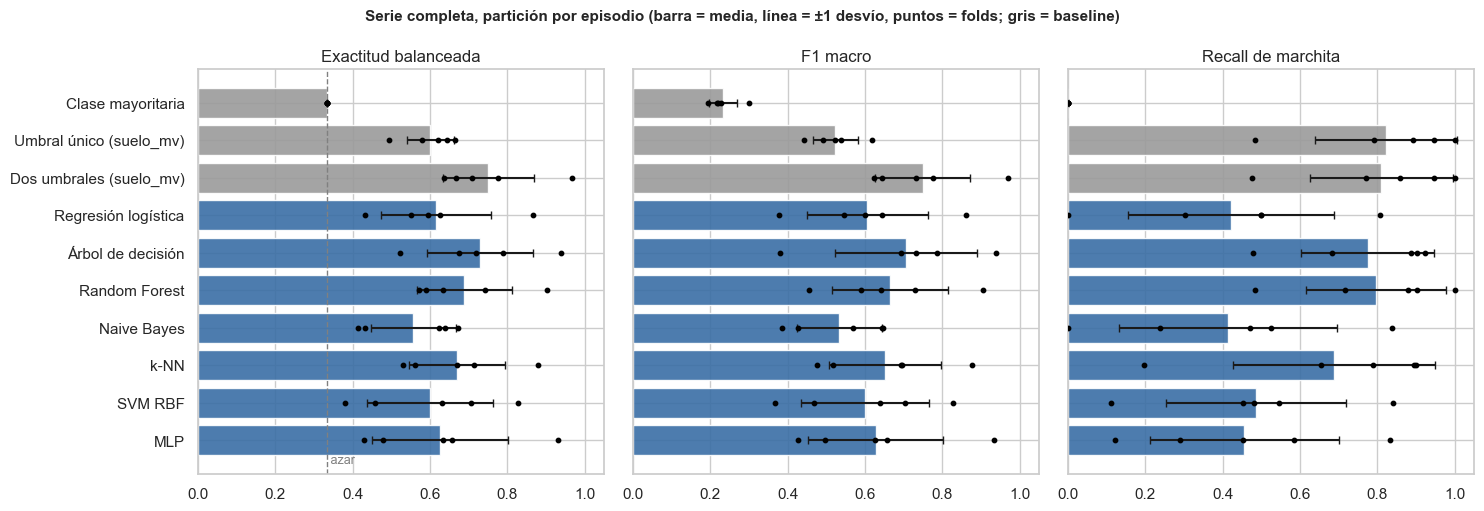

In [10]:
orden = list(MODELOS)
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), sharey=True)
for ax, m, titulo in zip(axes, ["exactitud_bal", "f1_macro", "recall_marchita"],
                         ["Exactitud balanceada", "F1 macro", "Recall de marchita"]):
    medias = [resultados[n]["folds"][m].mean() for n in orden]
    desv = [resultados[n]["folds"][m].std(ddof=0) for n in orden]
    colores = ["#9a9a9a" if ES_BASELINE[n] else "#3a6ea5" for n in orden]
    ax.barh(orden, medias, xerr=desv, color=colores, capsize=3, alpha=0.9)
    for i, n in enumerate(orden):
        pts = resultados[n]["folds"][m]
        ax.scatter(pts, np.full(len(pts), i), s=10, color="black", zorder=3)
    if m == "exactitud_bal":
        ax.axvline(1 / 3, ls="--", color="gray", lw=1)
        ax.text(1 / 3, len(orden) - 0.4, " azar", color="gray", fontsize=9)
    ax.set_xlim(0, 1.05)
    ax.set_title(titulo)
axes[0].invert_yaxis()
fig.suptitle("Serie completa, partición por episodio (barra = media, línea = ±1 desvío, puntos = folds; "
             "gris = baseline)", fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "comparacion_modelos.png")
plt.show()

figura: docs/entrega2/fig/matrices_confusion_candidatos.png


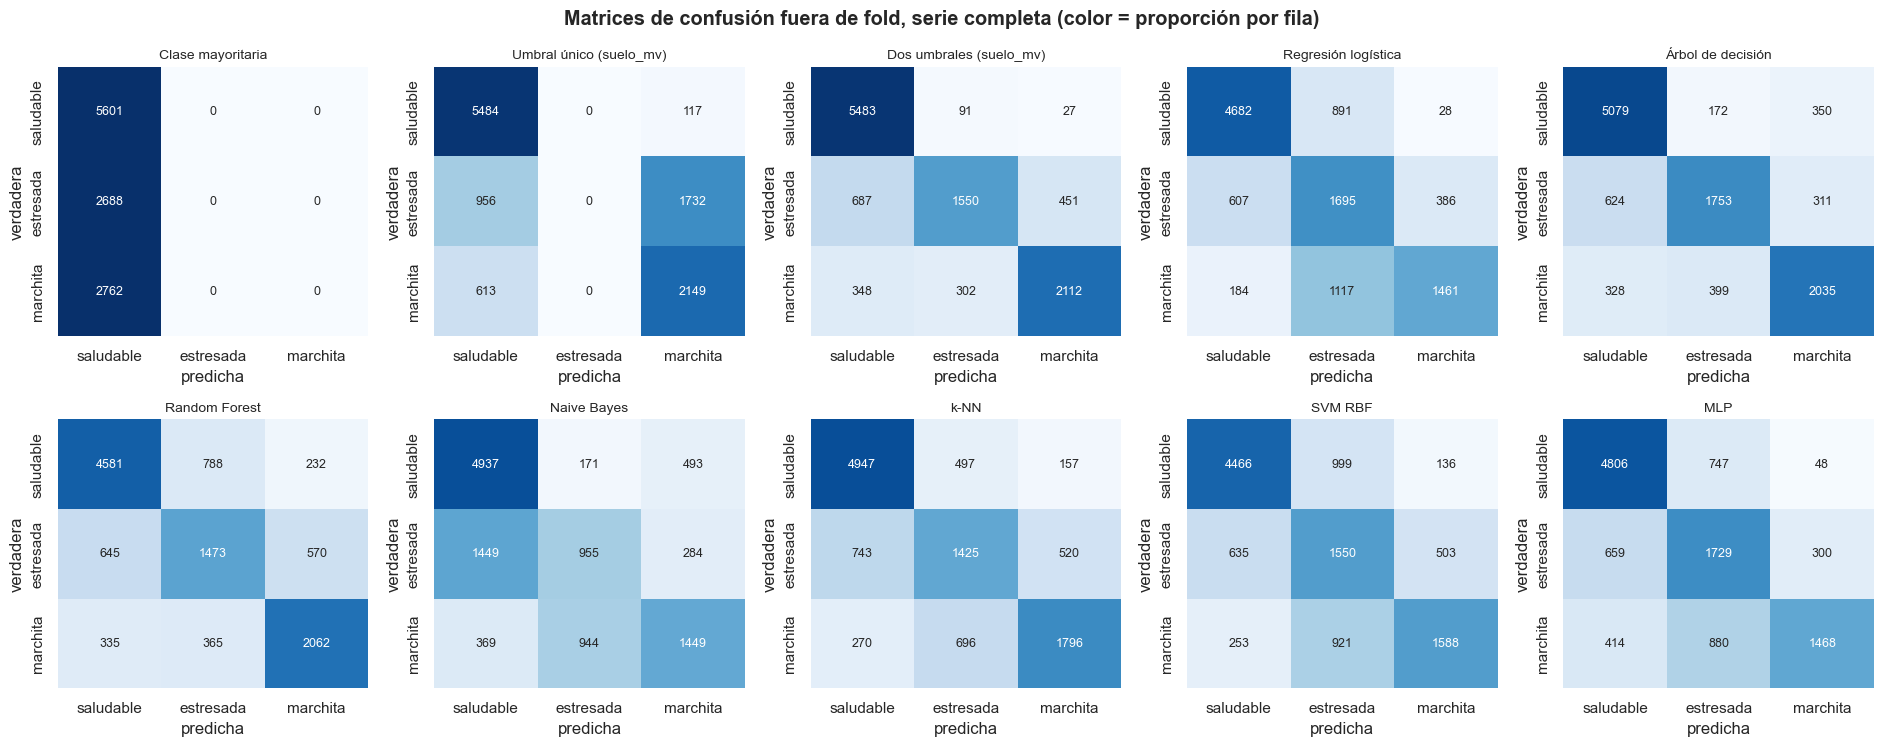

In [11]:
fig, axes = plt.subplots(2, 5, figsize=(19, 7.6))
for ax, n in zip(axes.flat, orden):
    cm = confusion_matrix(y, resultados[n]["oof"], labels=CODIGOS)
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=cm, fmt="d", cmap="Blues", vmin=0, vmax=1,
                xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ax, annot_kws={"size": 9})
    ax.set_title(n, fontsize=10)
    ax.set_xlabel("predicha")
    ax.set_ylabel("verdadera")
fig.suptitle("Matrices de confusión fuera de fold, serie completa (color = proporción por fila)",
             fontweight="bold")
fig.tight_layout()
guardar(fig, "matrices_confusion_candidatos.png")
plt.show()

**Lectura de §4** (espacio restringido: suelo + al menos una ambiental).

- **Ningún candidato le gana al baseline de dos umbrales sobre `suelo_mv`** en la serie completa (F1 macro 0,749 ± 0,123). El mejor candidato es el árbol (0,706 ± 0,183); el Random Forest cae de 0,744 (sin restricción, ejecución anterior) a 0,664 ± 0,150.
- **Las búsquedas eligen subconjuntos distintos en cada fold** (luz media, luz, HR, T, VPD…): ninguna ambiental se impone, señal de que aportan poco y de forma inestable.
- **El desvío entre folds es grande** (0,11–0,18 de F1). Con ~9 episodios de test por fold, las diferencias entre los mejores candidatos están dentro del ruido.
- Más abajo: Naive Bayes, regresión logística, SVM y MLP, el tocón de un solo umbral y la clase mayoritaria.


## 5. Costo en la ESP32, métricas sobre lo real y selección

### 5.1 Costo

Para el costo se reentrena cada candidato con la misma búsqueda (partición interna por episodio) sobre **toda** la serie: ese es el modelo que se exportaría. La estimación sale de `costo_esp32` (`modelos.py`): parámetros en `float` de 4 B en flash, RAM de trabajo durante la inferencia, operaciones por predicción y µs a 240 MHz (≈ 10 ciclos por operación y ≈ 1 µs por `expf`). Es un orden de magnitud para comparar; el tiempo del modelo elegido se mide en la placa (`t_us` del log `[INF]`). Todos se exportarían como tablas `static const` en flash: ninguno necesita memoria dinámica.

In [12]:
finales, costos, elegidos_full = {}, {}, {}
for nombre, (est, grilla) in MODELOS.items():
    if grilla:
        b = busqueda(est, grilla).fit(X, y, groups=g)
        finales[nombre] = b.best_estimator_
        elegidos_full[nombre] = b.best_params_
    else:
        finales[nombre] = clone(est).fit(X, y)
    costos[nombre] = costo_esp32(finales[nombre])

costo = pd.DataFrame(costos).T
costo["config"] = [describir(elegidos_full[n]) if n in elegidos_full else
                   f"[{nombre_subconjunto(finales[n].named_steps['sel'].columnas)}]"
                   for n in costo.index]
costo["flash_KB"] = costo.flash_B.astype(float) / 1024
display(costo[["config", "flash_B", "flash_KB", "ram_B", "ops", "exps", "t_us_est", "exportable"]])

,config,flash_B,flash_KB,ram_B,ops,exps,t_us_est,exportable
Clase mayoritaria,[todas],4,0.004,0,0,0,0.000,sí (constante)
Umbral único (suelo_mv),[suelo],51,0.050,16,2,0,0.083,sí (if/else o tablas)
Dos umbrales (suelo_mv),[suelo],8,0.008,0,2,0,0.083,sí (dos if)
Regresión logística,[suelo+delta+luz1h] C=0.01,72,0.070,24,33,3,4.375,sí (producto matriz-vector)
Árbol de decisión,"[suelo+delta+luz1h] max_depth=4, min_samples_l...",441,0.431,16,8,0,0.333,sí (if/else o tablas)
Random Forest,"[suelo+luz1h] max_depth=5, min_samples_leaf=100",17790,17.373,28,390,0,16.250,sí (tablas)
Naive Bayes,[suelo+luz1h],60,0.059,12,27,3,4.125,sí (fórmula cerrada)
k-NN,[suelo+delta+luz1h] n_neighbors=5,143687,140.319,56,121567,0,"5,065.292","sí, pero guarda todo el train"
SVM RBF,[suelo+delta+luz1h] C=1.0,117956,115.191,28,76654,5896,"9,089.917","sí, pero guarda los vectores soporte"
MLP,"[suelo+delta+luz1h] alpha=0.001, hidden_layer_...",260,0.254,64,124,3,8.167,sí (capas densas)


### 5.2 Métricas sobre los episodios reales

Las métricas de §4 se midieron sobre una serie que en su gran mayoría generó el simulador: dicen cuánto aprende el modelo **la regla del simulador**, no la planta. Antes de elegir se mide sobre lo que midió la placa, de tres maneras:

1. **Reales fuera de fold**: las predicciones de §4 (cada fila predicha por un modelo que no vio su episodio), quedándose sólo con las filas `real`. El train incluye los otros episodios reales y el relleno.
2. **Transferencia simulado → real**: entrenar (con la misma búsqueda por episodio) sólo con los episodios simulados y predecir todas las filas reales. Se excluyen enteros los episodios que tienen alguna fila real: los huecos chicos se rellenaron *dentro* de episodios reales y esas filas llevan la etiqueta observada. Es la prueba limpia de si lo que se aprendió del simulador sirve para la planta.
3. **Sólo reales** (referencia, §6): el mismo protocolo con los episodios reales nada más.

Cada una con y sin los episodios dudosos. Con tan pocos episodios reales las métricas se calculan juntando todas las filas reales (por fold quedarían 2 o 3 episodios); el N efectivo sigue siendo el de episodios.

In [13]:
sin_dud = es_real & ~dudoso
print(f"episodios reales: {df[es_real].episodio_id.nunique()} · sin dudosos: {df[sin_dud].episodio_id.nunique()} "
      f"(dudosos: {sorted(EPISODIOS_DUDOSOS)})")
control = {}
for n in orden:
    r = resultados[n]
    for etiqueta, m in [("reales fuera de fold", es_real), ("reales fuera de fold, sin dudosos", sin_dud)]:
        p = r["oof_p"][m] if np.isfinite(r["oof_p"][m]).all() else None
        control[(n, etiqueta)] = metricas(y[m], r["oof"][m], p)

ep_con_real = set(df[es_real].episodio_id)
solo_sim = ~df.episodio_id.isin(ep_con_real).to_numpy()
print(f"train de la transferencia: {solo_sim.sum():,} filas simuladas, {df[solo_sim].episodio_id.nunique()} episodios")
pred_sim2real = {}
for n, (est, grilla) in MODELOS.items():
    if grilla:
        mdl = busqueda(est, grilla).fit(X[solo_sim], y[solo_sim], groups=g[solo_sim]).best_estimator_
    else:
        mdl = clone(est).fit(X[solo_sim], y[solo_sim])
    pred_sim2real[n] = mdl.predict(X)
    pp = proba_3(mdl, X)
    for etiqueta, m in [("sim → real", es_real), ("sim → real, sin dudosos", sin_dud)]:
        control[(n, etiqueta)] = metricas(y[m], pred_sim2real[n][m], None if pp is None else pp[m])

tabla_control = pd.DataFrame(control).T
tabla_control.index.names = ["modelo", "evaluación"]
EVALS_SEL = ["reales fuera de fold", "reales fuera de fold, sin dudosos", "sim → real", "sim → real, sin dudosos"]
for m in ["exactitud_bal", "f1_macro", "recall_marchita"]:
    t = tabla_control[m].unstack("evaluación").reindex(index=orden, columns=EVALS_SEL)
    t.insert(0, "serie completa (CV, media)", resumen_cv[f"{m} (media)"])
    print(f"\n{m}")
    display(t)

episodios reales: 11 · sin dudosos: 7 (dudosos: [8, 9, 11, 14])
train de la transferencia: 9,228 filas simuladas, 36 episodios



exactitud_bal


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos"
modelo,,,,,
Clase mayoritaria,0.333,0.333,0.333,0.333,0.333
Umbral único (suelo_mv),0.601,0.534,0.664,0.442,0.664
Dos umbrales (suelo_mv),0.751,0.536,0.666,0.536,0.666
Regresión logística,0.614,0.452,0.575,0.433,0.549
Árbol de decisión,0.728,0.411,0.561,0.532,0.654
Random Forest,0.688,0.408,0.546,0.436,0.544
Naive Bayes,0.556,0.524,0.731,0.488,0.641
k-NN,0.671,0.413,0.537,0.556,0.717
SVM RBF,0.600,0.414,0.575,0.415,0.542



f1_macro


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos"
modelo,,,,,
Clase mayoritaria,0.232,0.162,0.213,0.162,0.213
Umbral único (suelo_mv),0.523,0.388,0.550,0.351,0.557
Dos umbrales (suelo_mv),0.749,0.389,0.551,0.389,0.551
Regresión logística,0.606,0.374,0.564,0.365,0.539
Árbol de decisión,0.706,0.328,0.502,0.386,0.542
Random Forest,0.664,0.329,0.483,0.323,0.462
Naive Bayes,0.534,0.476,0.731,0.416,0.634
k-NN,0.652,0.332,0.481,0.436,0.654
SVM RBF,0.601,0.370,0.571,0.331,0.499



recall_marchita


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos"
modelo,,,,,
Clase mayoritaria,0.000,0.000,0.000,0.000,0.000
Umbral único (suelo_mv),0.823,0.674,1.000,0.000,0.000
Dos umbrales (suelo_mv),0.811,0.674,1.000,0.674,1.000
Regresión logística,0.422,0.422,0.604,0.422,0.604
Árbol de decisión,0.775,0.652,0.968,0.696,1.000
Random Forest,0.797,0.674,1.000,0.593,0.866
Naive Bayes,0.415,0.407,0.604,0.407,0.604
k-NN,0.687,0.621,0.922,0.671,0.995
SVM RBF,0.487,0.432,0.641,0.575,0.829


### 5.3 Criterio de selección

El contrato (§5.3) pide el mejor F1 macro dentro de 1 desvío del mejor, con flash < 32 KB, sin memoria dinámica y < 1 ms, desempatando por interpretabilidad. Como el F1 de la serie completa mide sobre todo al simulador, se agrega un paso que pesa lo real. Las reglas se fijan antes de mirar quién gana:

1. **Restricciones duras**: flash < 32 KB, < 1 ms estimado, sin memoria dinámica.
2. **Serie completa**: F1 macro (CV por episodio) dentro de 1 desvío del mejor candidato.
3. **Real**: *puntaje real* = media del F1 macro en "reales fuera de fold, sin dudosos" y en "sim → real, sin dudosos". Pasan los que quedan dentro de 1 desvío del mejor puntaje real. El desvío sale de un *bootstrap por episodio*: se remuestrean los episodios reales no dudosos (estratificado por clase, 500 veces) y se recalcula el puntaje del mejor.
4. **Desempate**: interpretabilidad (árbol / umbral = 1 … caja negra = 5), después puntaje real.

Los baselines no son elegibles, pero se reporta si el elegido les gana.

In [14]:
LIMITE_FLASH_B, LIMITE_US = 32 * 1024, 1000
N_BOOT = 500
# Interpretabilidad para el desempate (1 = se lee entero en una hoja; 5 = caja negra).
INTERPRETABILIDAD = {"Clase mayoritaria": 1, "Umbral único (suelo_mv)": 1, "Dos umbrales (suelo_mv)": 1,
                     "Árbol de decisión": 1, "Regresión logística": 2, "Naive Bayes": 2,
                     "Random Forest": 3, "k-NN": 4, "SVM RBF": 5, "MLP": 5}


def f1m(y_, p_):
    return f1_score(y_, p_, labels=CODIGOS, average="macro", zero_division=0)


def puntaje_real(n, filas=None):
    m = sin_dud if filas is None else filas
    return 0.5 * (f1m(y[m], resultados[n]["oof"][m]) + f1m(y[m], pred_sim2real[n][m]))


# Bootstrap por episodio (estratificado por clase) sobre los episodios reales no dudosos.
ep_ok = df[sin_dud].groupby("episodio_id").clase.first()
filas_ep = {e: np.flatnonzero(sin_dud & (g == e)) for e in ep_ok.index}
rng = np.random.default_rng(0)
remuestras = []
for _ in range(N_BOOT):
    eps = np.concatenate([rng.choice(ep_ok[ep_ok == c].index, size=(ep_ok == c).sum(), replace=True)
                          for c in CLASES if (ep_ok == c).any()])
    remuestras.append(np.concatenate([filas_ep[e] for e in eps]))


def puntaje_boot(n):
    v = []
    for idx in remuestras:
        v.append(0.5 * (f1m(y[idx], resultados[n]["oof"][idx]) + f1m(y[idx], pred_sim2real[n][idx])))
    return np.array(v)


sel = pd.DataFrame({
    "f1_macro": resumen_cv["f1_macro (media)"],
    "f1_desvío": resumen_cv["f1_macro (desvío)"],
    "exactitud_bal": resumen_cv["exactitud_bal (media)"],
    "recall_marchita": resumen_cv["recall_marchita (media)"],
    "f1_reales_oof_sd": [f1m(y[sin_dud], resultados[n]["oof"][sin_dud]) for n in orden],
    "f1_sim2real_sd": [f1m(y[sin_dud], pred_sim2real[n][sin_dud]) for n in orden],
    "puntaje_real": [puntaje_real(n) for n in orden],
    "flash_B": costo.flash_B.astype(int), "ram_B": costo.ram_B.astype(int),
    "t_us_est": costo.t_us_est.astype(float),
    "interpretabilidad": pd.Series(INTERPRETABILIDAD),
}, index=orden)
sel["baseline"] = pd.Series(ES_BASELINE)
sel["restricciones_ok"] = (sel.flash_B < LIMITE_FLASH_B) & (sel.t_us_est < LIMITE_US)   # todas sin malloc
cand = sel[~sel.baseline]
mejor_cv = cand.f1_macro.idxmax()
piso_cv = cand.loc[mejor_cv, "f1_macro"] - cand.loc[mejor_cv, "f1_desvío"]
sel["cv_ok"] = sel.f1_macro >= piso_cv
pasan = sel[~sel.baseline & sel.restricciones_ok & sel.cv_ok]
mejor_real = pasan.puntaje_real.idxmax()
boot = puntaje_boot(mejor_real)
desvio_real = boot.std(ddof=0)
piso_real = pasan.loc[mejor_real, "puntaje_real"] - desvio_real
sel["real_ok"] = sel.puntaje_real >= piso_real
sel["cumple"] = ~sel.baseline & sel.restricciones_ok & sel.cv_ok & sel.real_ok

print(f"1) restricciones: fuera por costo → {', '.join(sel[~sel.restricciones_ok].index) or 'ninguno'}")
print(f"2) serie completa: mejor F1 = {mejor_cv} {cand.loc[mejor_cv, 'f1_macro']:.3f} ± "
      f"{cand.loc[mejor_cv, 'f1_desvío']:.3f} → piso {piso_cv:.3f}; pasan: {', '.join(pasan.index)}")
print(f"3) real: mejor puntaje = {mejor_real} {pasan.loc[mejor_real, 'puntaje_real']:.3f}, desvío bootstrap "
      f"por episodio {desvio_real:.3f} ({len(ep_ok)} episodios, {N_BOOT} remuestras) → piso {piso_real:.3f}")
aptos = sel[sel.cumple].sort_values(["interpretabilidad", "puntaje_real"], ascending=[True, False])
print(f"   cumplen todo: {', '.join(aptos.index)}")
elegido = aptos.index[0]
print(f"4) ELEGIDO (interpretabilidad, después puntaje real): {elegido}")
display(sel.drop(columns=["ram_B"]).sort_values("puntaje_real", ascending=False))

1) restricciones: fuera por costo → k-NN, SVM RBF
2) serie completa: mejor F1 = Árbol de decisión 0.706 ± 0.183 → piso 0.524; pasan: Regresión logística, Árbol de decisión, Random Forest, Naive Bayes, MLP
3) real: mejor puntaje = Naive Bayes 0.682, desvío bootstrap por episodio 0.154 (7 episodios, 500 remuestras) → piso 0.528
   cumplen todo: Naive Bayes, Regresión logística
4) ELEGIDO (interpretabilidad, después puntaje real): Naive Bayes


,f1_macro,f1_desvío,exactitud_bal,recall_marchita,f1_reales_oof_sd,f1_sim2real_sd,puntaje_real,flash_B,t_us_est,interpretabilidad,baseline,restricciones_ok,cv_ok,real_ok,cumple
Naive Bayes,0.534,0.109,0.556,0.415,0.731,0.634,0.682,60,4.125,2,False,True,True,True,True
k-NN,0.652,0.144,0.671,0.687,0.481,0.654,0.567,143687,"5,065.292",4,False,False,True,True,False
Umbral único (suelo_mv),0.523,0.058,0.601,0.823,0.550,0.557,0.553,51,0.083,1,True,True,False,True,False
Dos umbrales (suelo_mv),0.749,0.123,0.751,0.811,0.551,0.551,0.551,8,0.083,1,True,True,True,True,False
Regresión logística,0.606,0.157,0.614,0.422,0.564,0.539,0.551,72,4.375,2,False,True,True,True,True
SVM RBF,0.601,0.165,0.600,0.487,0.571,0.499,0.535,117956,"9,089.917",5,False,False,True,True,False
MLP,0.628,0.174,0.625,0.457,0.540,0.514,0.527,260,8.167,5,False,True,True,False,False
Árbol de decisión,0.706,0.183,0.728,0.775,0.502,0.542,0.522,441,0.333,1,False,True,True,False,False
Random Forest,0.664,0.150,0.688,0.797,0.483,0.462,0.473,17790,16.250,3,False,True,True,False,False
Clase mayoritaria,0.232,0.036,0.333,0.000,0.213,0.213,0.213,4,0.000,1,True,True,False,False,False


figura: docs/entrega2/fig/rendimiento_vs_costo.png


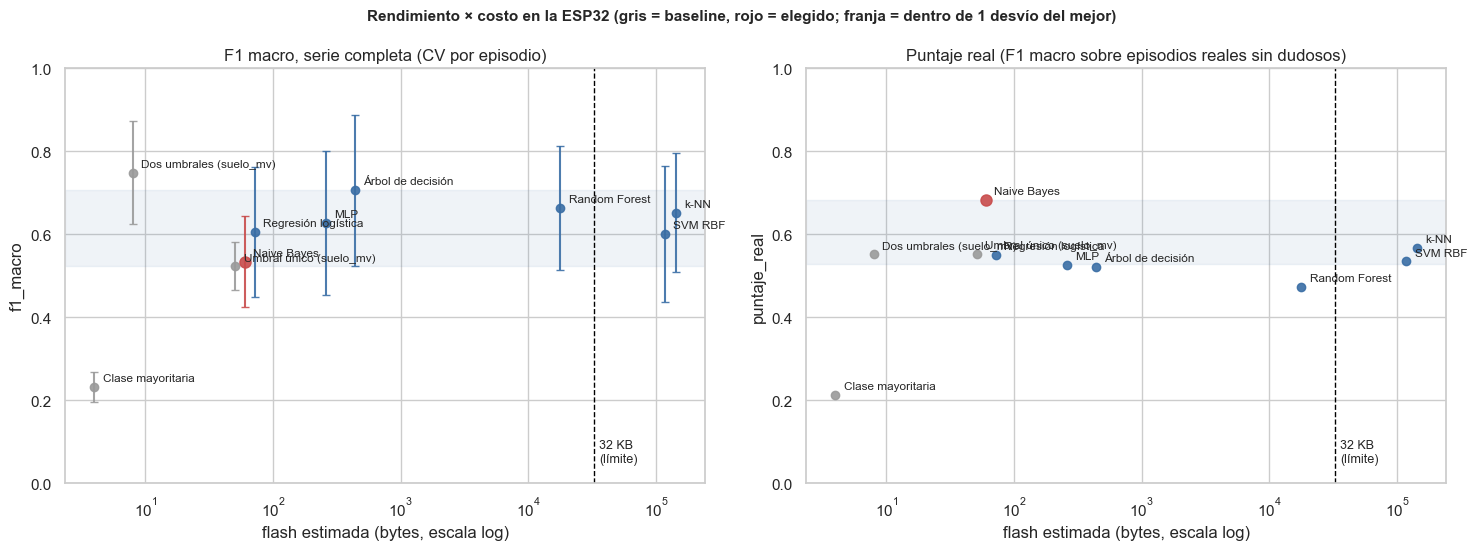

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.6), sharey=False)
for ax, (col, titulo) in zip(axes, [("f1_macro", "F1 macro, serie completa (CV por episodio)"),
                                    ("puntaje_real", "Puntaje real (F1 macro sobre episodios reales sin dudosos)")]):
    for n, r in sel.iterrows():
        color = "#9a9a9a" if r.baseline else ("#c84b4b" if n == elegido else "#3a6ea5")
        yerr = r["f1_desvío"] if col == "f1_macro" else None
        ax.errorbar(max(r.flash_B, 4), r[col], yerr=yerr, fmt="o", color=color,
                    ms=8 if n == elegido else 6, capsize=3, alpha=0.9)
        ax.annotate(n, (max(r.flash_B, 4), r[col]), textcoords="offset points", xytext=(6, 4), fontsize=8.5)
    ax.axvline(LIMITE_FLASH_B, color="black", ls="--", lw=1)
    ax.text(LIMITE_FLASH_B * 1.1, 0.05, "32 KB\n(límite)", fontsize=9)
    piso = piso_cv if col == "f1_macro" else piso_real
    techo = cand.loc[mejor_cv, "f1_macro"] if col == "f1_macro" else pasan.loc[mejor_real, "puntaje_real"]
    ax.axhspan(piso, techo, color="#3a6ea5", alpha=0.08)
    ax.set_xscale("log")
    ax.set(xlabel="flash estimada (bytes, escala log)", ylabel=col, ylim=(0, 1), title=titulo)
fig.suptitle("Rendimiento × costo en la ESP32 (gris = baseline, rojo = elegido; franja = dentro de 1 desvío del mejor)",
             fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "rendimiento_vs_costo.png")
plt.show()

### 5.4 El elegido contra el baseline de umbral

Comparación explícita con las reglas de umbral sobre `suelo_mv`, en la serie completa (fold por fold: los modelos ven exactamente los mismos episodios de test) y sobre lo real.

In [16]:
RIVALES = [elegido, "Dos umbrales (suelo_mv)", "Umbral único (suelo_mv)", "Clase mayoritaria"]
comp = sel.loc[RIVALES, ["f1_macro", "exactitud_bal", "recall_marchita", "f1_reales_oof_sd", "f1_sim2real_sd",
                         "puntaje_real", "flash_B"]]
display(comp)
for rival in RIVALES[1:3]:
    dif = resultados[elegido]["folds"].f1_macro - resultados[rival]["folds"].f1_macro
    print(f"F1 macro por fold, {elegido} − {rival}: {np.round(dif.values, 3)} "
          f"(media {dif.mean():+.3f}; gana en {(dif > 0).sum()} de {len(dif)})")
    d_real = sel.loc[elegido, "puntaje_real"] - sel.loc[rival, "puntaje_real"]
    b_r = puntaje_boot(elegido) - puntaje_boot(rival)
    print(f"   puntaje real: {d_real:+.3f}; en el bootstrap por episodio el elegido gana en "
          f"{(b_r > 0).mean():.0%} de las remuestras, empata en {(b_r == 0).mean():.0%}")

,f1_macro,exactitud_bal,recall_marchita,f1_reales_oof_sd,f1_sim2real_sd,puntaje_real,flash_B
Naive Bayes,0.534,0.556,0.415,0.731,0.634,0.682,60
Dos umbrales (suelo_mv),0.749,0.751,0.811,0.551,0.551,0.551,8
Umbral único (suelo_mv),0.523,0.601,0.823,0.550,0.557,0.553,51
Clase mayoritaria,0.232,0.333,0.000,0.213,0.213,0.213,4


F1 macro por fold, Naive Bayes − Dos umbrales (suelo_mv): [-0.401  0.003 -0.306 -0.238 -0.131] (media -0.215; gana en 1 de 5)


   puntaje real: +0.131; en el bootstrap por episodio el elegido gana en 62% de las remuestras, empata en 2%
F1 macro por fold, Naive Bayes − Umbral único (suelo_mv): [ 0.03   0.205 -0.067 -0.233  0.12 ] (media +0.011; gana en 3 de 5)


   puntaje real: +0.129; en el bootstrap por episodio el elegido gana en 64% de las remuestras, empata en 0%


### 5.5 Configuración final y export

Dentro del tipo elegido se aplica la misma regla de parsimonia: entre las configuraciones de la búsqueda sobre toda la serie con F1 macro interno dentro de 1 desvío de la mejor, la más simple (menos features, después menos profundidad). Tiene que coincidir con `CONFIG_FINAL` de `modelos.py`, que es lo que reentrena el exportador (`python -m plantaia_ml.exportar_c`), y su versión con la de `modelo_plantaia.h`. Si no coincide, la celda lo dice y hay que actualizar `CONFIG_FINAL`, re-exportar y volver a correr el notebook.

In [17]:
b_final = busqueda(*MODELOS[elegido]).fit(X, y, groups=g)
rk = pd.DataFrame(b_final.cv_results_)
rk["config"] = [describir(p) for p in rk.params]
rk["n_features"] = [len(p["sel__columnas"]) for p in rk.params]
rk["profundidad"] = [p.get("clf__max_depth", 0) for p in rk.params]
assert all(cumple_restriccion(p["sel__columnas"]) for p in rk.params), "restricción de diseño"
mejor_h = rk.loc[rk.mean_test_score.idxmax()]
piso_h = mejor_h.mean_test_score - mejor_h.std_test_score
rk["dentro_1_desvío"] = rk.mean_test_score >= piso_h
display(rk.sort_values("mean_test_score", ascending=False)
        [["config", "mean_test_score", "std_test_score", "n_features", "profundidad", "dentro_1_desvío"]]
        .head(10).reset_index(drop=True))
print(f"mejor configuración interna: {mejor_h.config} = {mejor_h.mean_test_score:.4f} ± {mejor_h.std_test_score:.4f}")

# Ranking de parsimonia: primero las configuraciones dentro de 1 desvío de la
# mejor, de la más simple a la más compleja (menos features, menos profundidad, mejor F1 interno);
# después las demás, por F1 interno. Se recorre en ese orden y se toma la primera que
#   (a) cumple las restricciones de la placa (flash < 32 KB, < 1 ms) y
#   (b) USA de verdad la ambiental: reemplazar sus features ambientales por la mediana de la serie
#       cambia la clase predicha en al menos MIN_CAMBIO_PCT % de las filas REALES.
# (b) se agregó DESPUÉS de ver resultados (decisión de producto, §5.6/§5.7). Existe porque "tener" una ambiental en el subconjunto no alcanza: un bosque puede no cortar nunca
# por ella (o cortar en una zona donde no cambia la clase) y el LED seguiría dependiendo sólo de la sonda.
# MIN_CAMBIO_PCT (= 1 %) viene de modelos.py.
MEDIANA_SERIE = np.median(X, axis=0)


def ambientales_de(mdl):
    return [int(c) for c in mdl.named_steps["sel"].columnas if int(c) in AMBIENTALES]


def pct_cambia(mdl, Xe, cols=None, ref=MEDIANA_SERIE):
    # % de filas de Xe cuya clase predicha cambia al poner las columnas `cols` en `ref` (por defecto,
    # todas las ambientales que usa el modelo, en la mediana de la serie).
    cols = ambientales_de(mdl) if cols is None else list(cols)
    Xm = Xe.copy()
    Xm[:, cols] = ref[cols]
    return 100 * (mdl.predict(Xm) != mdl.predict(Xe)).mean()


ranking = pd.concat([
    rk[rk.dentro_1_desvío].sort_values(["n_features", "profundidad", "rank_test_score"], kind="stable"),
    rk[~rk.dentro_1_desvío].sort_values("rank_test_score", kind="stable")])
probadas, simple = [], None
for _, r in ranking.iterrows():
    mdl_c = clone(MODELOS[elegido][0]).set_params(**r.params).fit(X, y)
    cst = costo_esp32(mdl_c)
    pct = pct_cambia(mdl_c, X[es_real])
    ok_costo = cst["flash_B"] < LIMITE_FLASH_B and cst["t_us_est"] < LIMITE_US
    probadas.append({"config": r.config, "F1 interno": r.mean_test_score, "desvío": r.std_test_score,
                     "dentro_1_desvío": r.dentro_1_desvío, "flash_B": cst["flash_B"],
                     "% reales que cambian (ambiental → mediana)": pct,
                     "cumple": ok_costo and pct >= MIN_CAMBIO_PCT})
    if ok_costo and pct >= MIN_CAMBIO_PCT:
        simple = r
        break
tabla_probadas = pd.DataFrame(probadas)
print(f"configuraciones probadas en orden de parsimonia hasta la primera que usa la ambiental "
      f"(≥ {MIN_CAMBIO_PCT:g} % de las filas reales):")
display(tabla_probadas)
assert simple is not None, "ninguna configuración del tipo elegido usa la ambiental: pasar al siguiente tipo"
print(f"configuración final: {simple.config} = {simple.mean_test_score:.4f} "
      f"({'dentro' if simple.dentro_1_desvío else 'FUERA'} de 1 desvío de la mejor)")
tipo_original = elegido
config_original = dict(simple.params)
print(f"→ criterio original en el espacio restringido: {tipo_original} {describir(config_original)} "
      "(se revisa con la condición de seguridad en §5.6)")


,config,mean_test_score,std_test_score,n_features,profundidad,dentro_1_desvío
0,[suelo+luz1h],0.549,0.086,2,0,True
1,[suelo+luz],0.548,0.087,2,0,True
2,[suelo+luz+luz1h],0.545,0.089,3,0,True
3,[suelo+delta+luz1h],0.530,0.178,3,0,True
4,[suelo+delta+luz],0.529,0.178,3,0,True
5,[suelo+delta+vpd],0.521,0.187,3,0,True
6,[suelo+hr],0.514,0.118,2,0,True
7,[suelo+hr+luz],0.510,0.119,3,0,True
8,[suelo+hr+luz1h],0.508,0.121,3,0,True
9,[suelo+delta+hr],0.508,0.168,3,0,True


mejor configuración interna: [suelo+luz1h] = 0.5490 ± 0.0860
configuraciones probadas en orden de parsimonia hasta la primera que usa la ambiental (≥ 1 % de las filas reales):


,config,F1 interno,desvío,dentro_1_desvío,flash_B,% reales que cambian (ambiental → mediana),cumple
0,[suelo+luz1h],0.549,0.086,True,60,0.984,False
1,[suelo+luz],0.548,0.087,True,60,0.984,False
2,[suelo+hr],0.514,0.118,True,60,0.908,False
3,[suelo+temp],0.496,0.134,True,60,2.120,True


configuración final: [suelo+temp] = 0.4964 (dentro de 1 desvío de la mejor)
→ criterio original en el espacio restringido: Naive Bayes [suelo+temp] (se revisa con la condición de seguridad en §5.6)


### 5.6 Condición de seguridad: no perder la marchita real

**Declaración honesta.** Esta condición y la compuerta de influencia ambiental de §5.5 (≥ 1 % de filas reales que cambian de clase) **se agregaron después de ver los resultados**, por decisión de producto. No estaban en el criterio pre-registrado de §5.3.

- **Qué pasó.** El criterio de §5.3, aplicado en el espacio restringido, eligió un Naive Bayes (`suelo+temp`) que no reconoce la marchita real de octubre: 0 % del ep. 12, recall de marchita real 0,60 sin dudosos.
- **Por qué se agrega.** El error caro es **no avisar marchita** (`docs/ENTREGA2.md` §5.1), y un semáforo que no se pone en rojo ante la única marchita observada de octubre no sirve, aunque gane en F1.

**Condición de seguridad** (`modelos.py`), sobre las filas reales fuera de fold y sin dudosos:

- recall de `marchita` ≥ 0,9, **y**
- el ep. 12 con ≥ 50 % de sus filas bien.

**Cómo se elige ahora.**

- **Grilla explícita** de configuraciones fijas (`modelos.configuraciones_seguridad`): suelo + cada ambiental y suelo + cada par de ambientales, con:
  - regresión logística (C 0,01 / 0,1 / 1; monótona, sin el artefacto de "sonda muy mojada → rojo");
  - árbol (prof. 2 / 3 / 4, hoja 100);
  - Random Forest chico de 30 árboles (prof. 3 / 5, hoja 20 / 100);
  - Naive Bayes.

  Son 165 configuraciones. Cada una se evalúa con los mismos 5 folds por episodio, y además entrenada sólo con simulado (sim → real) y con toda la serie.
- **Filtros, en orden:**
  1. costo (flash < 32 KB, < 1 ms);
  2. influencia ambiental ≥ 1 % (modelo con toda la serie, filas reales);
  3. condición de seguridad.
- **Entre las que pasan, el criterio de §5.3 como antes:**
  - F1 macro de la serie (CV por episodio) dentro de 1 desvío de la mejor;
  - puntaje real dentro de 1 desvío bootstrap por episodio del mejor;
  - desempate por interpretabilidad, después menos features, después puntaje real.
- **Chequeo extra:** con la sonda fuera del rango real (900–1140 mV, más mojada que cualquier lectura) y T normal, el elegido no debe dar `marchita`.
- **Si ninguna configuración cumple, no se fuerza nada:** `CONFIG_FINAL` queda en el Naive Bayes de §5.5 y se documenta.


In [18]:
from joblib import Parallel, delayed

folds_ext = list(particion_externa().split(X, y, g))
e12_real = es_real & (g == EP_MARCHITA_OCTUBRE)
X_mojado = np.tile(np.median(X[es_real & (df.ts >= "2026-10-01").to_numpy()], axis=0), (241, 1)).astype(np.float32)
X_mojado[:, 0] = np.linspace(900, 1140, 241)      # más mojado que cualquier lectura real (mín. ~1405 mV)
X_mojado[:, 1] = 0.0


def explorar(tipo, params):
    est = clone(MODELOS[tipo][0]).set_params(**params)
    oof_c, f1_f = np.zeros(len(y), int), []
    for tr, te in folds_ext:
        oof_c[te] = clone(est).fit(X[tr], y[tr]).predict(X[te])
        f1_f.append(f1m(y[te], oof_c[te]))
    s2r_c = clone(est).fit(X[solo_sim], y[solo_sim]).predict(X)
    completo = clone(est).fit(X, y)
    cst = costo_esp32(completo)
    return {"tipo": tipo, "config": describir(params), "params": params,
            "n_features": len(params["sel__columnas"]), "f1_serie": np.mean(f1_f), "f1_desvío": np.std(f1_f),
            "puntaje_real": 0.5 * (f1m(y[sin_dud], oof_c[sin_dud]) + f1m(y[sin_dud], s2r_c[sin_dud])),
            "recall_marchita_oof_sd": recall_marchita(y[sin_dud], oof_c[sin_dud]),
            "ep12_oof": (oof_c[e12_real] == 3).mean(),
            "recall_marchita_s2r_sd": recall_marchita(y[sin_dud], s2r_c[sin_dud]),
            "ep12_s2r": (s2r_c[e12_real] == 3).mean(),
            "exactitud_bal_oof": balanced_accuracy_score(y[es_real], oof_c[es_real]),
            "exactitud_bal_oof_sd": balanced_accuracy_score(y[sin_dud], oof_c[sin_dud]),
            "pct_influencia": pct_cambia(completo, X[es_real]),
            "pct_marchita_sonda_mojada": 100 * (completo.predict(X_mojado) == 3).mean(),
            "flash_B": cst["flash_B"], "t_us_est": cst["t_us_est"],
            "interpretabilidad": INTERPRETABILIDAD[tipo], "_oof": oof_c, "_s2r": s2r_c}


t0 = time.perf_counter()
filas_ex = Parallel(n_jobs=-1)(delayed(explorar)(t, p) for t, p in configuraciones_seguridad())
explor = pd.DataFrame(filas_ex)
print(f"{len(explor)} configuraciones exploradas en {time.perf_counter() - t0:.0f} s")
explor["costo_ok"] = (explor.flash_B < LIMITE_FLASH_B) & (explor.t_us_est < LIMITE_US)
explor["influencia_ok"] = explor.pct_influencia >= MIN_CAMBIO_PCT
explor["seguridad_ok"] = ((explor.recall_marchita_oof_sd >= MIN_RECALL_MARCHITA)
                          & (explor.ep12_oof >= MIN_ACIERTO_EP12))
explor["pasa_filtros"] = explor.costo_ok & explor.influencia_ok & explor.seguridad_ok
embudo = explor.groupby("tipo").agg(configuraciones=("config", "size"), costo=("costo_ok", "sum"),
                                    seguridad=("seguridad_ok", "sum"),
                                    **{"costo + influencia": ("influencia_ok", lambda s: int((s & explor.loc[s.index, "costo_ok"]).sum()))},
                                    **{"costo + influencia + seguridad": ("pasa_filtros", "sum")},
                                    max_recall_marchita=("recall_marchita_oof_sd", "max"), max_ep12=("ep12_oof", "max"))
print("Cuántas configuraciones de cada tipo pasan cada filtro:")
display(embudo)
COLS_EX = ["tipo", "config", "f1_serie", "f1_desvío", "puntaje_real", "recall_marchita_oof_sd", "ep12_oof",
           "pct_influencia", "pct_marchita_sonda_mojada", "flash_B", "costo_ok", "influencia_ok", "seguridad_ok"]
print("La mejor configuración (por puntaje real) de cada tipo, pase o no los filtros:")
display(explor.sort_values("puntaje_real", ascending=False).groupby("tipo").head(1)[COLS_EX].set_index(["tipo", "config"]))


165 configuraciones exploradas en 4 s
Cuántas configuraciones de cada tipo pasan cada filtro:


,configuraciones,costo,seguridad,costo + influencia,costo + influencia + seguridad,max_recall_marchita,max_ep12
tipo,,,,,,,
Naive Bayes,15,15,0,12,0,0.604,0.000
Random Forest,60,60,54,40,36,1.000,1.000
Regresión logística,45,45,0,42,0,0.604,0.000
Árbol de decisión,45,45,35,0,0,1.000,1.000


La mejor configuración (por puntaje real) de cada tipo, pase o no los filtros:


,,f1_serie,f1_desvío,puntaje_real,recall_marchita_oof_sd,ep12_oof,pct_influencia,pct_marchita_sonda_mojada,flash_B,costo_ok,influencia_ok,seguridad_ok
tipo,config,,,,,,,,,,,
Naive Bayes,[suelo+temp],0.589,0.156,0.736,0.604,0.000,2.120,99.170,60,True,True,False
Random Forest,"[suelo+hr+vpd] max_depth=3, min_samples_leaf=100",0.726,0.131,0.682,1.000,1.000,6.737,0.000,6690,True,True,True
Árbol de decisión,"[suelo+luz] max_depth=4, min_samples_leaf=100",0.745,0.078,0.656,1.000,1.000,0.000,0.000,411,True,False,True
Regresión logística,[suelo+temp+vpd] C=1.0,0.586,0.159,0.574,0.604,0.000,5.678,0.000,72,True,True,False


In [19]:
# Criterio de §5.3 + puntaje real, entre las configuraciones que pasan costo, influencia y seguridad.
def puntaje_boot_cfg(fila):
    return np.array([0.5 * (f1m(y[idx], fila["_oof"][idx]) + f1m(y[idx], fila["_s2r"][idx])) for idx in remuestras])


aptas = explor[explor.pasa_filtros].copy()
if aptas.empty:
    print("NINGUNA configuración cumple costo + influencia ambiental + seguridad: CONFIG_FINAL queda en "
          f"el criterio original ({tipo_original} {describir(config_original)}).")
    final_tipo, final_params = tipo_original, config_original
else:
    mejor_cv_s = aptas.f1_serie.idxmax()
    piso_cv_s = aptas.loc[mejor_cv_s, "f1_serie"] - aptas.loc[mejor_cv_s, "f1_desvío"]
    aptas["cv_ok"] = aptas.f1_serie >= piso_cv_s
    pasan_s = aptas[aptas.cv_ok]
    mejor_real_s = pasan_s.puntaje_real.idxmax()
    desvio_real_s = puntaje_boot_cfg(explor.loc[mejor_real_s]).std(ddof=0)
    piso_real_s = pasan_s.loc[mejor_real_s, "puntaje_real"] - desvio_real_s
    aptas["real_ok"] = aptas.cv_ok & (aptas.puntaje_real >= piso_real_s)
    print(f"pasan costo + influencia + seguridad: {len(aptas)} configuraciones "
          f"({', '.join(f'{k}: {v}' for k, v in aptas.tipo.value_counts().items())})")
    print(f"serie completa: mejor F1 = {aptas.loc[mejor_cv_s, 'tipo']} {aptas.loc[mejor_cv_s, 'config']} "
          f"{aptas.loc[mejor_cv_s, 'f1_serie']:.3f} ± {aptas.loc[mejor_cv_s, 'f1_desvío']:.3f} → piso {piso_cv_s:.3f}; "
          f"pasan {int(aptas.cv_ok.sum())}")
    print(f"real: mejor puntaje = {pasan_s.loc[mejor_real_s, 'tipo']} {pasan_s.loc[mejor_real_s, 'config']} "
          f"{pasan_s.loc[mejor_real_s, 'puntaje_real']:.3f}, desvío bootstrap por episodio {desvio_real_s:.3f} "
          f"→ piso {piso_real_s:.3f}; pasan {int(aptas.real_ok.sum())}")
    finalistas = (aptas[aptas.real_ok]
                  .sort_values(["interpretabilidad", "n_features", "puntaje_real"], ascending=[True, True, False]))
    display(finalistas[COLS_EX + ["interpretabilidad"]].set_index(["tipo", "config"]))
    final_tipo, final_params = finalistas.iloc[0].tipo, dict(finalistas.iloc[0].params)
    print(f"ELEGIDO con la condición de seguridad (interpretabilidad, menos features, puntaje real): "
          f"{final_tipo} {describir(final_params)}")
tabla_candidatos_seg = (explor.sort_values(["pasa_filtros", "puntaje_real"], ascending=False)[COLS_EX]
                        .set_index(["tipo", "config"]))


pasan costo + influencia + seguridad: 36 configuraciones (Random Forest: 36)
serie completa: mejor F1 = Random Forest [suelo+vpd] max_depth=3, min_samples_leaf=20 0.755 ± 0.121 → piso 0.634; pasan 36
real: mejor puntaje = Random Forest [suelo+hr+vpd] max_depth=3, min_samples_leaf=100 0.682, desvío bootstrap por episodio 0.048 → piso 0.634; pasan 14


f1_serie  f1_desvío  puntaje_real  recall_marchita_oof_sd  ep12_oof  pct_influencia  \
tipo          config                                                                                                                                    
Random Forest [suelo+vpd] max_depth=5, min_samples_leaf=20           0.720      0.141         0.661                   1.000     1.000           2.498   
              [suelo+temp] max_depth=5, min_samples_leaf=20          0.692      0.144         0.660                   1.000     1.000          11.128   
              [suelo+temp] max_depth=5, min_samples_leaf=100         0.715      0.133         0.656                   1.000     1.000           9.235   
              [suelo+vpd] max_depth=5, min_samples_leaf=100          0.747      0.125         0.654                   1.000     1.000           6.283   
              [suelo+temp] max_depth=3, min_samples_leaf=100         0.729      0.126         0.644                   1.000     1.000           2.498   
              [suelo+temp] max_depth=3, min_samples_leaf=20          0.752      0.125         0.642                   1.000     1.000           2.498   
              [suelo+hr] max_depth=5, min_samples_leaf=100           0.738      0.124         0.635                   1.000     1.000           8.100   
              [suelo+hr+vpd] max_depth=3, min_samples_leaf=100       0.726      0.131         0.682                   1.000     1.000           6.737   
              [suelo+temp+vpd] max_depth=5, min_samples_leaf=20      0.699      0.119         0.663                   1.000     1.000           6.132   
              [suelo+temp+luz] max_depth=5, min_samples_leaf=20      0.729      0.118         0.649                   1.000     1.000           3.861   
              [suelo+temp+luz] max_depth=5, min_samples_leaf=100     0.705      0.134         0.647                   1.000     1.000           5.526   
              [suelo+temp+vpd] max_depth=5, min_samples_leaf=100     0.700      0.149         0.644                   1.000     1.000           3.936   
              [suelo+vpd+luz] max_depth=5, min_samples_leaf=20       0.735      0.100         0.641                   1.000     1.000           5.375   
              [suelo+temp+hr] max_depth=5, min_samples_leaf=100      0.703      0.138         0.635                   1.000     1.000           3.861   

                                                                  pct_marchita_sonda_mojada  flash_B  costo_ok  influencia_ok  seguridad_ok  interpretabilidad  
tipo          config                                                                                                                                            
Random Forest [suelo+vpd] max_depth=5, min_samples_leaf=20                            0.000    23730      True           True          True                  3  
              [suelo+temp] max_depth=5, min_samples_leaf=20                           0.000    22440      True           True          True                  3  
              [suelo+temp] max_depth=5, min_samples_leaf=100                          0.000    17040      True           True          True                  3  
              [suelo+vpd] max_depth=5, min_samples_leaf=100                           0.000    18180      True           True          True                  3  
              [suelo+temp] max_depth=3, min_samples_leaf=100                          0.000     6720      True           True          True                  3  
              [suelo+temp] max_depth=3, min_samples_leaf=20                           0.000     6930      True           True          True                  3  
              [suelo+hr] max_depth=5, min_samples_leaf=100                            0.000    18390      True           True          True                  3  
              [suelo+hr+vpd] max_depth=3, min_samples_leaf=100                        0.000     6690      True           True          True                  3  
       

ELEGIDO con la condición de seguridad (interpretabilidad, menos features, puntaje real): Random Forest [suelo+vpd] max_depth=5, min_samples_leaf=20


In [20]:
# Modelo de la placa: tiene que coincidir con CONFIG_FINAL y con el header exportado.
elegido = final_tipo
print("CONFIG_FINAL en modelos.py:", CONFIG_FINAL["tipo"], describir(CONFIG_FINAL["params"]))
coincide = CONFIG_FINAL["tipo"] == final_tipo and set(final_params) == set(CONFIG_FINAL["params"]) and all(
    (tuple(final_params[k]) if k == "sel__columnas" else final_params[k]) == v for k, v in CONFIG_FINAL["params"].items())
print("→ coincide con CONFIG_FINAL" if coincide else
      "→ ¡NO COINCIDE! Actualizar CONFIG_FINAL en modelos.py, re-exportar y re-ejecutar.")

modelo = modelo_final().fit(X, y)
assert cumple_restriccion(modelo.named_steps["sel"].columnas), "el modelo de la placa no usa ninguna ambiental"
version = version_modelo(modelo)
en_header = next(l.split('"')[1] for l in RUTA_MODELO.read_text().splitlines()
                 if "PLANTAIA_MODELO_VERSION" in l and "#define" in l)
print(f"versión del modelo (CONFIG_FINAL reentrenado ahora): {version} · en modelo_plantaia.h: {en_header}")
print("→ el header está al día" if version == en_header else
      "→ ¡HEADER DESACTUALIZADO! correr: cd ml && python -m plantaia_ml.exportar_c")

# Sonda fuera del rango real (más mojada que cualquier lectura) con T normal: no debe dar marchita.
p_moj = modelo.predict(X_mojado)
print(f"sonda 900–1140 mV, resto en la mediana real de octubre (T = {X_mojado[0, 2]:.1f} °C): "
      + ", ".join(f"{CLASES[k - 1]} {100 * (p_moj == k).mean():.0f} %" for k in CODIGOS))
X_seca = X_mojado.copy()
X_seca[:, 0] = np.linspace(3000, 3124, 241)
print("sonda 3000–3124 mV (más seca que todo lo real salvo septiembre):",
      ", ".join(f"{CLASES[k - 1]} {100 * (modelo.predict(X_seca) == k).mean():.0f} %" for k in CODIGOS))


CONFIG_FINAL en modelos.py: Random Forest [suelo+vpd] max_depth=5, min_samples_leaf=20
→ coincide con CONFIG_FINAL
versión del modelo (CONFIG_FINAL reentrenado ahora): rf-f04-7734f6 · en modelo_plantaia.h: rf-f04-7734f6
→ el header está al día
sonda 900–1140 mV, resto en la mediana real de octubre (T = 19.8 °C): saludable 100 %, estresada 0 %, marchita 0 %
sonda 3000–3124 mV (más seca que todo lo real salvo septiembre): saludable 0 %, estresada 0 %, marchita 100 %


**El modelo final y el del criterio original, lado a lado.** Se agrega el % de filas predichas `marchita` en la ventana post-arranque que el filtrado descarta. Ahí la sonda baja rápido por el transitorio y `suelo_delta_1h` mide deriva, no secado. Ninguno de los dos modelos usa `suelo_delta_1h`.


In [21]:
todo_pb = serie_maceta01(filtrado=False)
todo_pb = todo_pb[(todo_pb.fuente == "real") & todo_pb.valido & todo_pb.post_boot]
Xpb = matriz_X(todo_pb)
filas_cfg = {}
pares = [("CONFIG_FINAL", CONFIG_FINAL["tipo"], CONFIG_FINAL["params"]),
         ("criterio original (sin seguridad)", tipo_original, config_original)]
for etiqueta, tipo_c, params in pares:
    est_c = clone(MODELOS[tipo_c][0]).set_params(**params)
    r_c = evaluar(est_c, {}, X, y, g)
    completo = clone(est_c).fit(X, y)
    filas_cfg[f"{etiqueta}: {tipo_c} {describir(params)}"] = {
        "F1 macro serie (CV)": r_c["folds"].f1_macro.mean(),
        "F1 macro reales fuera de fold, sin dudosos": f1m(y[sin_dud], r_c["oof"][sin_dud]),
        "exactitud bal. reales fuera de fold": balanced_accuracy_score(y[es_real], r_c["oof"][es_real]),
        "% reales predichas marchita": 100 * (completo.predict(X[es_real]) == 3).mean(),
        "% marchita en la ventana post-arranque descartada": 100 * (completo.predict(Xpb) == 3).mean()
        if len(Xpb) else np.nan,
    }
print(f"% real de marchita en las filas reales: {100 * (y[es_real] == 3).mean():.1f} % · "
      f"filas reales en la ventana post-arranque: {len(Xpb)}")
display(pd.DataFrame(filas_cfg).T)

fija = evaluar(modelo_final(), {}, X, y, g)
print("\nConfiguración final fija (sin búsqueda) vs. búsqueda anidada del tipo, serie completa:")
display(tabla_metricas({"config. final fija": fija, f"{CONFIG_FINAL['tipo']} (búsqueda anidada)":
                        resultados[CONFIG_FINAL["tipo"]]}))
print("costo:", costo_esp32(modelo))
print()
# Barrido de suelo_mv con el resto de las features en la mediana de la serie y delta = 0: es un corte
# del modelo con el ambiente "típico". Cómo se mueve con el ambiente está en §5.6.
xs = np.arange(900, 3200.25, 0.25)
Xgrid = np.tile(np.median(X, axis=0), (len(xs), 1)).astype(np.float32)
Xgrid[:, 0] = xs
Xgrid[:, 1] = 0.0
pred_grid = modelo.predict(Xgrid)
proba_grid = modelo.predict_proba(Xgrid)
cambios = np.flatnonzero(np.diff(pred_grid)) + 1
umbrales_final = [float(xs[i]) for i in cambios]
tramos = np.split(np.arange(len(xs)), cambios)
print("features que usa:", [FEATURES[c] for c in modelo.named_steps["sel"].columnas])
print("clase predicha por tramo de suelo_mv (mV), con las ambientales en la mediana de la serie:")
for t in tramos:
    print(f"  {xs[t[0]]:7.2f} – {xs[t[-1]]:7.2f}  → {CLASES[pred_grid[t[0]] - 1]}")
if hasattr(modelo.named_steps["clf"], "tree_"):
    print(export_text(modelo.named_steps["clf"],
                      feature_names=[FEATURES[c] for c in modelo.named_steps["sel"].columnas], decimals=1))

% real de marchita en las filas reales: 24.4 % · filas reales en la ventana post-arranque: 136


,F1 macro serie (CV),"F1 macro reales fuera de fold, sin dudosos",exactitud bal. reales fuera de fold,% reales predichas marchita,% marchita en la ventana post-arranque descartada
"CONFIG_FINAL: Random Forest [suelo+vpd] max_depth=5, min_samples_leaf=20",0.720,0.663,0.557,23.164,42.647
criterio original (sin seguridad): Naive Bayes [suelo+temp],0.589,0.741,0.529,16.578,53.676



Configuración final fija (sin búsqueda) vs. búsqueda anidada del tipo, serie completa:


,exactitud_bal,f1_macro,recall_marchita,roc_auc_ovr
config. final fija,0.728 ± 0.135,0.720 ± 0.141,0.733 ± 0.288,0.808 ± 0.093
Random Forest (búsqueda anidada),0.688 ± 0.123,0.664 ± 0.150,0.797 ± 0.181,0.820 ± 0.103


costo: {'flash_B': 23730, 'ram_B': 28, 'ops': 390, 'exps': 0, 't_us_est': 16.25, 'exportable': 'sí (tablas)'}

features que usa: ['suelo_mv', 'vpd_kpa']
clase predicha por tramo de suelo_mv (mV), con las ambientales en la mediana de la serie:
   900.00 – 1638.75  → saludable
  1639.00 – 1739.75  → estresada
  1740.00 – 1845.25  → marchita
  1845.50 – 2096.00  → estresada
  2096.25 – 3200.00  → marchita


figura: docs/entrega2/fig/modelo_final_suelo_mv.png


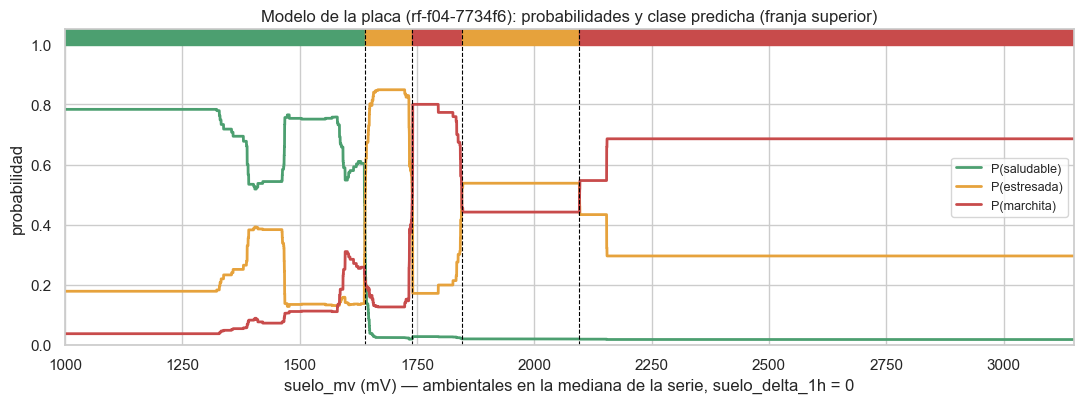

figura: docs/entrega2/fig/matriz_confusion_final.png


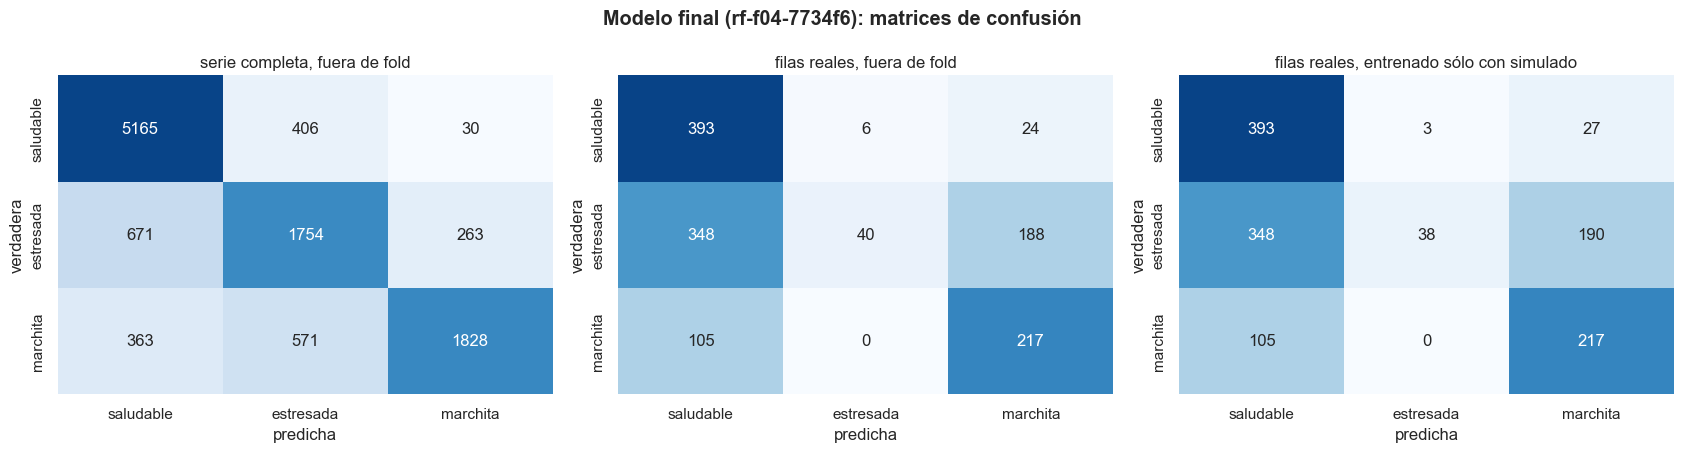

In [22]:
clf_final = modelo.named_steps["clf"]
if hasattr(clf_final, "tree_"):
    fig, ax = plt.subplots(figsize=(11, 5.2))
    plot_tree(clf_final, feature_names=[FEATURES[c] for c in modelo.named_steps["sel"].columnas],
              class_names=CLASES, filled=True, impurity=False, proportion=True, rounded=True,
              precision=2, fontsize=10, ax=ax)
    ax.set_title(f"Modelo de la placa: {version} (proporciones con class_weight='balanced')", fontweight="bold")
    guardar(fig, "arbol_final.png")
    plt.show()
else:
    (FIGURAS / "arbol_final.png").unlink(missing_ok=True)   # de una ejecución anterior con un árbol

# El modelo final como función de suelo_mv: probabilidad de cada clase y clase predicha.
fig, ax = plt.subplots(figsize=(11, 4.2))
for k, c in enumerate(CLASES):
    ax.plot(xs, proba_grid[:, k], color=COLORES[c], lw=2, label=f"P({c})")
for t in tramos:
    ax.axvspan(xs[t[0]], xs[t[-1]], ymin=0.95, ymax=1.0, color=COLORES[CLASES[pred_grid[t[0]] - 1]])
for u in umbrales_final:
    ax.axvline(u, color="black", ls="--", lw=0.8)
ax.set(xlabel="suelo_mv (mV) — ambientales en la mediana de la serie, suelo_delta_1h = 0",
       ylabel="probabilidad", ylim=(0, 1.05), xlim=(1000, 3150),
       title=f"Modelo de la placa ({version}): probabilidades y clase predicha (franja superior)")
ax.legend(loc="center right", fontsize=9)
fig.tight_layout()
guardar(fig, "modelo_final_suelo_mv.png")
plt.show()

oof_fija = fija["oof"]
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for ax, (titulo, pred, m) in zip(axes, [
        ("serie completa, fuera de fold", oof_fija, np.ones(len(y), bool)),
        ("filas reales, fuera de fold", oof_fija, es_real),
        ("filas reales, entrenado sólo con simulado", None, es_real)]):
    if pred is None:
        est_s = clone(modelo_final()).fit(X[solo_sim], y[solo_sim])
        pred = est_s.predict(X)
    cm = confusion_matrix(y[m], pred[m], labels=CODIGOS)
    sns.heatmap(cm / cm.sum(axis=1, keepdims=True).clip(1), annot=cm, fmt="d", cmap="Blues", vmin=0,
                vmax=1, xticklabels=CLASES, yticklabels=CLASES, cbar=False, ax=ax)
    ax.set(title=titulo, xlabel="predicha", ylabel="verdadera")
fig.suptitle(f"Modelo final ({version}): matrices de confusión", fontweight="bold")
fig.tight_layout()
guardar(fig, "matriz_confusion_final.png")
plt.show()

**Lectura de la selección.**

**1) Criterio original de §5.3, en el espacio restringido** (§5.3–§5.5):

- **Costo.** k-NN y SVM quedan afuera (115–140 KB).
- **Serie completa.** El mejor F1 es el árbol (0,706 ± 0,183) → piso 0,524.
- **Real.** Naive Bayes tiene el mejor puntaje (0,682, desvío bootstrap 0,154). Pasa también la regresión logística, y gana Naive Bayes por puntaje.
- **Configuración.** La compuerta de influencia deja afuera `suelo+luz1h`, `suelo+luz` y `suelo+hr` (≤ 0,98 % de cambios) y queda **NB `suelo+temp`** (`nb-f02-fa0df4`).
- **Problema.** Ese modelo **no reconoce la marchita real de octubre**: 0 % del ep. 12, recall de marchita real 0,60. Además da `marchita` con la sonda muy mojada (99 % entre 900 y 1140 mV).

**2) Con la condición de seguridad** (§5.6, agregada después de ver lo anterior), sobre 165 configuraciones explícitas:

| tipo | configuraciones | pasan seguridad | pasan costo + influencia | pasan las tres |
|---|---|---|---|---|
| Regresión logística | 45 | 0 | 42 | 0 |
| Naive Bayes | 15 | 0 | 12 | 0 |
| Árbol (prof. 2–4) | 45 | 35 | 0 | 0 |
| Random Forest chico | 60 | 54 | 40 | **36** |

- **Ninguna regresión logística ni ningún Naive Bayes** reconoce el ep. 12 (máximo 0 %; recall de marchita real ≤ 0,60). Un modelo monótono en la sonda no puede poner la marchita de octubre (1758 mV) debajo de la estresada de septiembre (2050 mV) y del ep. 13 (1930 mV).
- **Los árboles** que cumplen la seguridad no usan la ambiental: como mucho cambian el 0,98 % de las filas reales.
- **Entre los 36 RF:**
  - F1 de la serie: el mejor es `suelo+vpd` prof. 3 (0,755 ± 0,121) → piso 0,634; pasan los 36.
  - Puntaje real: el mejor es `suelo+hr+vpd` prof. 3 (0,682), con desvío bootstrap 0,048 → piso 0,634; pasan 14.
  - Desempate: misma interpretabilidad, menos features, después puntaje real.
  - Gana **RF `suelo+vpd`, prof. 5, hoja 20** (puntaje 0,661), por 0,001 sobre `suelo+temp` prof. 5. Es un empate práctico.

**Elegido: Random Forest de 30 árboles, `max_depth=5`, `min_samples_leaf=20`, con `suelo_mv` y `vpd_kpa`** (`rf-f04-7734f6`).

- **Costo.** 23.730 B de flash estimados (1570 nodos, 800 hojas; 72 % de 32 KB), ~390 operaciones, ~16 µs estimados.
- **Sonda fuera del rango real.** Mojada (900–1140 mV) → `saludable` 100 %; seca (3000–3124 mV) → `marchita` 100 %. No tiene el artefacto del Naive Bayes.
- **Configuración fija en la serie.** F1 0,720 ± 0,141, exactitud bal. 0,728 ± 0,135.
- **Contra los dos umbrales.**
  - Empata en la serie (0,720 contra 0,749, dentro del desvío).
  - Sobre lo real gana en puntaje (0,661 contra 0,551).
  - En exactitud balanceada real gana con todos los episodios (0,557 contra 0,536), sin dudosos (0,723 contra 0,666) y sin dudosos ni el 13 (0,809 contra 0,666).
  - Igual son 7 episodios no dudosos y 1–2 deciden.

**Qué es el modelo.** Con el VPD en la mediana (~1,2 kPa, el aire de octubre) es la misma función escalonada que el sólo-suelo:

| `suelo_mv` (mV) | clase |
|---|---|
| < 1639 | saludable |
| 1639–1740 | estresada |
| 1740–1845 | marchita (octubre, ep. 12) |
| 1845–2096 | estresada (septiembre / ep. 13) |
| > 2096 | marchita |

Sigue sin ser monótona: superpone las escalas de septiembre y octubre de la sonda. El VPD corre esos cortes (§5.7).


### 5.7 Restricción de diseño: el modelo debe usar variables ambientales

**La decisión.** En la ejecución anterior el criterio eligió un Random Forest que usaba **sólo `suelo_mv`** (`rf-f0-c42286`): el LED de la placa respondía únicamente a la sonda. Se decidió que eso está mal como producto:

- La sonda es **resistiva y deriva**: la misma marchita marcaba ~2830 mV en septiembre y ~1758 mV en octubre.
- La maceta tiene sensores de ambiente que el semáforo ignoraba.

Por eso todo candidato con selección de features se busca dentro de **`suelo_mv` + al menos una ambiental** (`temp_c`, `hum_aire_pct`, `vpd_kpa`, `luz_mv`, `luz_media_1h`; `suelo_delta_1h` no cuenta). Es una **restricción de producto, no un resultado de las métricas**.

**Declaración honesta sobre el criterio.**

- **(a) Agregados después de ver resultados.** La compuerta de influencia (≥ 1 % de filas reales que cambian de clase, §5.5) y la condición de seguridad (recall de marchita real ≥ 0,9 y ep. 12 ≥ 50 %, §5.6) **se agregaron después de ver los resultados**, por decisión de producto: el error caro es no avisar marchita (`docs/ENTREGA2.md` §5.1).
  - El criterio pre-registrado de §5.3, solo, elegía el Naive Bayes `suelo+temp`.
  - Las comparaciones de abajo muestran los dos.
  - Elegir con reglas puestas después de mirar infla el resultado del elegido: sus números sobre lo real son optimistas.
- **(b) De dónde sale la influencia ambiental.** ~88 % del entrenamiento es **simulado**. En el simulador la clase depende del ambiente **por reglas escritas a mano**:
  - marchitez transitoria cuando la demanda (luz × VPD) supera lo que da el sustrato;
  - secado más rápido con VPD alto;
  - radiador y freezer.

  La dirección "más VPD → más grave" viene de esas reglas. Lo que se puede comprobar con lo medido está más abajo, y es poco: 2 episodios reales.

**Cómo se verifica**, siempre sobre las filas **medidas**:

1. importancia por permutación;
2. % de filas reales cuya clase cambia si la ambiental va a su mediana, y en qué episodios y hacia dónde;
3. barrido con `suelo_mv` fijo en valores típicos de octubre y la ambiental en su rango real;
4. si la ambiental actúa como proxy de la hora (V de Cramér clase ~ franja = 0,47 en lo real).


In [23]:
# Comparación con el modelo sólo-suelo de la ejecución anterior (rf-f0-c42286): misma receta (RF 30 árboles,
# prof. 5, hoja 20) sin la restricción. Se reentrena acá para compararlo con exactamente los mismos folds.
SOLO_SUELO = {"sel__columnas": (0,), "clf__max_depth": 5, "clf__min_samples_leaf": 20}
est_ss = clone(MODELOS["Random Forest"][0]).set_params(**SOLO_SUELO)
mdl_ss = clone(est_ss).fit(X, y)
version_ss = version_modelo(mdl_ss)
print(f"sólo-suelo reentrenado: {version_ss} (el de la ejecución anterior era rf-f0-c42286 → "
      f"{'idéntico' if version_ss == 'rf-f0-c42286' else 'DISTINTO'})")
fija_ss = evaluar(est_ss, {}, X, y, g)
pred_ss_sim = clone(est_ss).fit(X[solo_sim], y[solo_sim]).predict(X)
mdl_sim = clone(modelo_final()).fit(X[solo_sim], y[solo_sim])     # el nuevo, entrenado sólo con simulado
pred_nuevo_sim = mdl_sim.predict(X)
# El modelo del criterio original en el espacio restringido (sin la condición de seguridad).
est_nb = clone(MODELOS[tipo_original][0]).set_params(**config_original)
mdl_nb = clone(est_nb).fit(X, y)
version_nb = version_modelo(mdl_nb)
fija_nb = evaluar(est_nb, {}, X, y, g)
pred_nb_sim = clone(est_nb).fit(X[solo_sim], y[solo_sim]).predict(X)

es_13 = (g == 13)
MASCARAS = {"todos": es_real, "sin dudosos": sin_dud, "sin el 13": es_real & ~es_13,
            "sin dudosos ni el 13": sin_dud & ~es_13}
DU = "Dos umbrales (suelo_mv)"
k_ss, k_nb, k_nv = f"sólo suelo ({version_ss})", f"criterio original ({version_nb})", f"nuevo ({version})"
COMPARADOS = {k_ss: (fija_ss["oof"], pred_ss_sim),
              k_nb: (fija_nb["oof"], pred_nb_sim),
              k_nv: (fija["oof"], pred_nuevo_sim),
              "dos umbrales (baseline)": (resultados[DU]["oof"], pred_sim2real[DU])}
filas_cmp = []
for nombre_m, (oof_m, s2r_m) in COMPARADOS.items():
    for ev, pred in [("reales fuera de fold", oof_m), ("sim → real", s2r_m)]:
        for mk, m in MASCARAS.items():
            filas_cmp.append({"modelo": nombre_m, "evaluación": ev, "episodios": mk,
                              "exactitud_bal": balanced_accuracy_score(y[m], pred[m]),
                              "f1_macro": f1m(y[m], pred[m]), "recall_marchita": recall_marchita(y[m], pred[m])})
comparacion = pd.DataFrame(filas_cmp).set_index(["modelo", "evaluación", "episodios"])
for met in ["exactitud_bal", "f1_macro", "recall_marchita"]:
    print(f"\n{met} sobre las filas REALES")
    display(comparacion[met].unstack("episodios")[list(MASCARAS)])


def puntaje_fijo(oof_m, s2r_m, idx=None):
    m = sin_dud if idx is None else idx
    return 0.5 * (f1m(y[m], oof_m[m]) + f1m(y[m], s2r_m[m]))


resumen_cmp = pd.DataFrame({
    n: {"F1 macro serie (CV, config. fija)": f"{r_f['folds'].f1_macro.mean():.3f} ± {r_f['folds'].f1_macro.std(ddof=0):.3f}",
        "puntaje real (config. fija)": puntaje_fijo(*COMPARADOS[n]),
        "flash estimada (costo_esp32, float, B)": costo_esp32(m_f)["flash_B"],
        "flash del header exportado (B)": bytes_parametros_c(m_f) if not isinstance(
            m_f.named_steps["clf"], UmbralesOrdenados) else np.nan,   # baseline: no se exporta
        "recall marchita reales oof s/d": recall_marchita(y[sin_dud], COMPARADOS[n][0][sin_dud]),
        "ep. 12 oof": (COMPARADOS[n][0][e12_real] == 3).mean(), "features": ", ".join(FEATURES[c] for c in m_f.named_steps["sel"].columnas)}
    for n, r_f, m_f in [(k_ss, fija_ss, mdl_ss), (k_nb, fija_nb, mdl_nb), (k_nv, fija, modelo),
                        ("dos umbrales (baseline)", resultados[DU], finales[DU])]}).T
display(resumen_cmp)
b_dif = np.array([puntaje_fijo(*COMPARADOS[k_nv], idx) - puntaje_fijo(*COMPARADOS[k_ss], idx) for idx in remuestras])
print(f"puntaje real nuevo − sólo suelo: {puntaje_fijo(*COMPARADOS[k_nv]) - puntaje_fijo(*COMPARADOS[k_ss]):+.3f} "
      f"(bootstrap por episodio: el nuevo gana en {(b_dif > 0).mean():.0%} de las remuestras, empata en "
      f"{(b_dif == 0).mean():.0%}; desvío de la diferencia {b_dif.std(ddof=0):.3f})")
dif_f = fija["folds"].f1_macro - fija_ss["folds"].f1_macro
print(f"F1 macro serie por fold, nuevo − sólo suelo: {np.round(dif_f.values, 3)} (media {dif_f.mean():+.3f})")


sólo-suelo reentrenado: rf-f0-c42286 (el de la ejecución anterior era rf-f0-c42286 → idéntico)



exactitud_bal sobre las filas REALES


episodios                                               todos  sin dudosos  sin el 13  sin dudosos ni el 13
modelo                            evaluación                                                               
criterio original (nb-f02-fa0df4) reales fuera de fold  0.529        0.741      0.451                 0.555
                                  sim → real            0.523        0.730      0.445                 0.531
dos umbrales (baseline)           reales fuera de fold  0.536        0.666      0.536                 0.666
                                  sim → real            0.536        0.666      0.536                 0.666
nuevo (rf-f04-7734f6)             reales fuera de fold  0.557        0.723      0.565                 0.809
                                  sim → real            0.556        0.720      0.563                 0.802
sólo suelo (rf-f0-c42286)         reales fuera de fold  0.487        0.644      0.494                 0.724
                                  sim → real            0.557        0.717      0.563                 0.797


f1_macro sobre las filas REALES


episodios                                               todos  sin dudosos  sin el 13  sin dudosos ni el 13
modelo                            evaluación                                                               
criterio original (nb-f02-fa0df4) reales fuera de fold  0.483        0.741      0.376                 0.556
                                  sim → real            0.476        0.730      0.366                 0.530
dos umbrales (baseline)           reales fuera de fold  0.389        0.551      0.427                 0.608
                                  sim → real            0.389        0.551      0.427                 0.608
nuevo (rf-f04-7734f6)             reales fuera de fold  0.442        0.663      0.497                 0.827
                                  sim → real            0.439        0.658      0.492                 0.819
sólo suelo (rf-f0-c42286)         reales fuera de fold  0.399        0.591      0.449                 0.698
                                  sim → real            0.439        0.655      0.492                 0.814


recall_marchita sobre las filas REALES


episodios                                               todos  sin dudosos  sin el 13  sin dudosos ni el 13
modelo                            evaluación                                                               
criterio original (nb-f02-fa0df4) reales fuera de fold  0.407        0.604      0.407                 0.604
                                  sim → real            0.407        0.604      0.407                 0.604
dos umbrales (baseline)           reales fuera de fold  0.674        1.000      0.674                 1.000
                                  sim → real            0.674        1.000      0.674                 1.000
nuevo (rf-f04-7734f6)             reales fuera de fold  0.674        1.000      0.674                 1.000
                                  sim → real            0.674        1.000      0.674                 1.000
sólo suelo (rf-f0-c42286)         reales fuera de fold  0.677        1.000      0.677                 1.000
                                  sim → real            0.677        1.000      0.677                 1.000

,"F1 macro serie (CV, config. fija)",puntaje real (config. fija),"flash estimada (costo_esp32, float, B)",flash del header exportado (B),recall marchita reales oof s/d,ep. 12 oof,features
sólo suelo (rf-f0-c42286),0.715 ± 0.112,0.623,24600,24660,1.000,1.000,suelo_mv
criterio original (nb-f02-fa0df4),0.589 ± 0.156,0.736,60,122,0.604,0.000,"suelo_mv, temp_c"
nuevo (rf-f04-7734f6),0.720 ± 0.141,0.661,23730,23790,1.000,1.000,"suelo_mv, vpd_kpa"
dos umbrales (baseline),0.749 ± 0.123,0.551,8,NaN,1.000,1.000,suelo_mv


puntaje real nuevo − sólo suelo: +0.038 (bootstrap por episodio: el nuevo gana en 100% de las remuestras, empata en 0%; desvío de la diferencia 0.019)
F1 macro serie por fold, nuevo − sólo suelo: [ 0.082 -0.137  0.04   0.023  0.017] (media +0.005)


In [24]:
# Verificación con las filas MEDIDAS de que las ambientales influyen. Dos modelos:
#   · "final": el de la placa (entrenado con toda la serie; las filas reales están en su train).
#   · "sim → real": misma configuración entrenada sólo con los episodios simulados (no vio ninguna fila real).
cols_amb = ambientales_de(modelo)
print("features del modelo nuevo:", [FEATURES[c] for c in modelo.named_steps["sel"].columnas],
      "· ambientales:", [FEATURES[c] for c in cols_amb])
Xr_ = X[es_real]
yr_ = y[es_real]
N_PERM = 30
rng_p = np.random.default_rng(0)
filas_pi = []
for etiqueta, mdl in [("final", modelo), ("sim → real", mdl_sim)]:
    base_p = mdl.predict(Xr_)
    base_ba = balanced_accuracy_score(yr_, base_p)
    for c in modelo.named_steps["sel"].columnas:
        caidas, cambios = [], []
        for _ in range(N_PERM):
            Xp = Xr_.copy()
            Xp[:, c] = rng_p.permutation(Xp[:, c])
            pp = mdl.predict(Xp)
            caidas.append(base_ba - balanced_accuracy_score(yr_, pp))
            cambios.append(100 * (pp != base_p).mean())
        filas_pi.append({"modelo": etiqueta, "feature": FEATURES[c],
                         "caída exactitud bal. (media)": np.mean(caidas), "desvío": np.std(caidas),
                         "% predicciones que cambian (media)": np.mean(cambios)})
importancia = pd.DataFrame(filas_pi).set_index(["modelo", "feature"])
print(f"\nImportancia por permutación sobre las {es_real.sum():,} filas reales ({N_PERM} permutaciones):")
display(importancia)

# % de filas reales cuya predicción cambia al poner la(s) ambiental(es) en la mediana.
filas_med = []
franja_r = (((df.ts - pd.Timedelta(hours=3)).dt.hour // 3) * 3)[es_real].to_numpy()
noche_r = ((df.ts - pd.Timedelta(hours=3)).dt.hour)[es_real].pipe(lambda h: (h >= 22) | (h < 8)).to_numpy()
for etiqueta, mdl in [("final", modelo), ("sim → real", mdl_sim)]:
    for nombre_c, cols in [(FEATURES[c], [c]) for c in cols_amb] + ([("todas las ambientales", cols_amb)] if len(cols_amb) > 1 else []):
        for ref_n, ref in [("mediana de la serie", MEDIANA_SERIE), ("mediana de lo real", np.median(Xr_, axis=0))]:
            Xm = Xr_.copy()
            Xm[:, cols] = ref[cols]
            camb = mdl.predict(Xm) != mdl.predict(Xr_)
            filas_med.append({"modelo": etiqueta, "ambiental → mediana": nombre_c, "referencia": ref_n,
                              "% filas reales que cambian": 100 * camb.mean(),
                              "filas": int(camb.sum()),
                              "episodios afectados": int(len(np.unique(g[es_real][camb]))),
                              "% de los cambios de noche (22–8 h)": 100 * noche_r[camb].mean() if camb.any() else np.nan})
cambio_mediana = pd.DataFrame(filas_med).set_index(["modelo", "ambiental → mediana", "referencia"])
print(f"(de noche son el {100 * noche_r.mean():.0f} % de las filas reales)")
display(cambio_mediana)
pct_cambio_final = pct_cambia(modelo, Xr_)
print(f"→ el modelo de la placa cambia la clase de {pct_cambio_final:.1f} % de las filas reales si se le saca "
      f"la información ambiental (compuerta de §5.5, fijada después de ver resultados: ≥ {MIN_CAMBIO_PCT:g} %): "
      f"{'CUMPLE' if pct_cambio_final >= MIN_CAMBIO_PCT else 'NO CUMPLE'}")

# Qué episodios reales cambian y hacia dónde (agregado por episodio).
Xm = Xr_.copy()
Xm[:, cols_amb] = MEDIANA_SERIE[cols_amb]
p_con, p_sin = modelo.predict(Xr_), modelo.predict(Xm)
d_r = df[es_real].assign(con=p_con, sin=p_sin)
cambios_ep = (d_r.groupby("episodio_id")
              .apply(lambda d: pd.Series({"clase": d.clase.iloc[0], "dudoso": bool(d.dudoso.iloc[0]), "filas": len(d),
                                          "% cambia": 100 * (d.con != d.sin).mean(),
                                          "acierto con ambiente": (d.con == d.clase_codigo).mean(),
                                          "acierto ambiental en mediana": (d.sin == d.clase_codigo).mean()}),
                     include_groups=False))
display(cambios_ep)


features del modelo nuevo: ['suelo_mv', 'vpd_kpa'] · ambientales: ['vpd_kpa']



Importancia por permutación sobre las 1,321 filas reales (30 permutaciones):

caída exactitud bal. (media)  desvío  % predicciones que cambian (media)
modelo     feature                                                                           
final      suelo_mv                         0.300   0.010                              51.289
           vpd_kpa                          0.021   0.004                               5.307
sim → real suelo_mv                         0.241   0.010                              48.251
           vpd_kpa                          0.026   0.005                               8.183

(de noche son el 45 % de las filas reales)


% filas reales que cambian  filas  episodios afectados  % de los cambios de noche (22–8 h)
modelo     ambiental → mediana referencia                                                                                                     
final      vpd_kpa             mediana de la serie                       2.498     33                    2                               0.000
                               mediana de lo real                        2.498     33                    2                               0.000
sim → real vpd_kpa             mediana de la serie                       2.877     38                    1                               0.000
                               mediana de lo real                        2.877     38                    1                               0.000

→ el modelo de la placa cambia la clase de 2.5 % de las filas reales si se le saca la información ambiental (compuerta de §5.5, fijada después de ver resultados: ≥ 1 %): CUMPLE


,clase,dudoso,filas,% cambia,acierto con ambiente,acierto ambiental en mediana
episodio_id,,,,,,
1,marchita,False,131,0.000,1.000,1.000
3,estresada,False,23,0.000,0.000,0.000
6,estresada,False,69,24.638,0.913,0.754
8,marchita,True,105,0.000,0.000,0.000
9,estresada,True,51,0.000,0.000,0.000
10,saludable,False,137,0.000,0.978,0.978
11,saludable,True,27,0.000,0.000,0.000
12,marchita,False,86,0.000,1.000,1.000
13,estresada,False,136,11.765,0.743,0.860


In [25]:
# Barrido: suelo_mv fijo en valores típicos de octubre (medidos) y cada ambiental del modelo recorriendo su
# rango REAL (percentil 1–99 de las filas reales); el resto en la mediana de lo real de octubre, delta = 0.
octubre = es_real & (df.ts >= "2026-10-01").to_numpy()
med_oct = np.median(X[octubre], axis=0)
med_oct[1] = 0.0
SUELOS_OCT = {
    "saludable oct. (mediana real)": float(np.median(X[octubre & (y == 1), 0])),
    "marchita ep. 12 (mediana)": float(np.median(X[g == 12, 0][es_real[g == 12]])),
    "estresada ep. 13 (mediana)": float(np.median(X[g == 13, 0][es_real[g == 13]])),
}
SUELOS_OCT["entre saludable y marchita"] = round((SUELOS_OCT["saludable oct. (mediana real)"]
                                                 + SUELOS_OCT["marchita ep. 12 (mediana)"]) / 2)
filas_b = []
barridos = {}
for c in cols_amb:
    lo, hi = np.percentile(X[es_real, c], [1, 99])
    vals = np.linspace(lo, hi, 400).astype(np.float32)
    for nombre_s, s in SUELOS_OCT.items():
        Xg = np.tile(med_oct, (len(vals), 1)).astype(np.float32)
        Xg[:, 0] = s
        Xg[:, c] = vals
        pr = modelo.predict(Xg)
        barridos[(FEATURES[c], nombre_s)] = (vals, pr)
        cortes = np.flatnonzero(np.diff(pr)) + 1
        tramos_b = np.split(np.arange(len(vals)), cortes)
        desc = " | ".join(f"{vals[t[0]]:.4g}–{vals[t[-1]]:.4g}: {CLASES[pr[t[0]] - 1]}" for t in tramos_b)
        filas_b.append({"ambiental": FEATURES[c], "rango real": f"{lo:.4g}–{hi:.4g}",
                        "suelo_mv fijo": f"{s:.0f} ({nombre_s})", "cambia la clase": len(cortes) > 0,
                        "clases que recorre": desc})
tabla_barrido = pd.DataFrame(filas_b)
with pd.option_context("display.max_colwidth", 200):
    display(tabla_barrido)
print(f"barridos en los que la ambiental cambia la clase: {tabla_barrido['cambia la clase'].sum()} de {len(tabla_barrido)}")


,ambiental,rango real,suelo_mv fijo,cambia la clase,clases que recorre
0,vpd_kpa,0.3996–4.153,1480 (saludable oct. (mediana real)),True,0.3996–0.5031: saludable | 0.5125–0.5784: estresada | 0.5878–4.153: saludable
1,vpd_kpa,0.3996–4.153,1758 (marchita ep. 12 (mediana)),True,0.3996–0.4655: marchita | 0.4749–0.6912: estresada | 0.7006–4.153: marchita
2,vpd_kpa,0.3996–4.153,1930 (estresada ep. 13 (mediana)),True,0.3996–1.049: estresada | 1.058–1.162: marchita | 1.171–1.359: estresada | 1.369–1.528: marchita | 1.538–1.557: estresada | 1.566–2.074: marchita | 2.083–2.601: estresada | 2.61–4.04: marchita | 4...
3,vpd_kpa,0.3996–4.153,1619 (entre saludable y marchita),True,0.3996–0.4655: marchita | 0.4749–0.5784: estresada | 0.5878–4.153: saludable


barridos en los que la ambiental cambia la clase: 4 de 4


figura: docs/entrega2/fig/modelo_final_sensibilidad.png


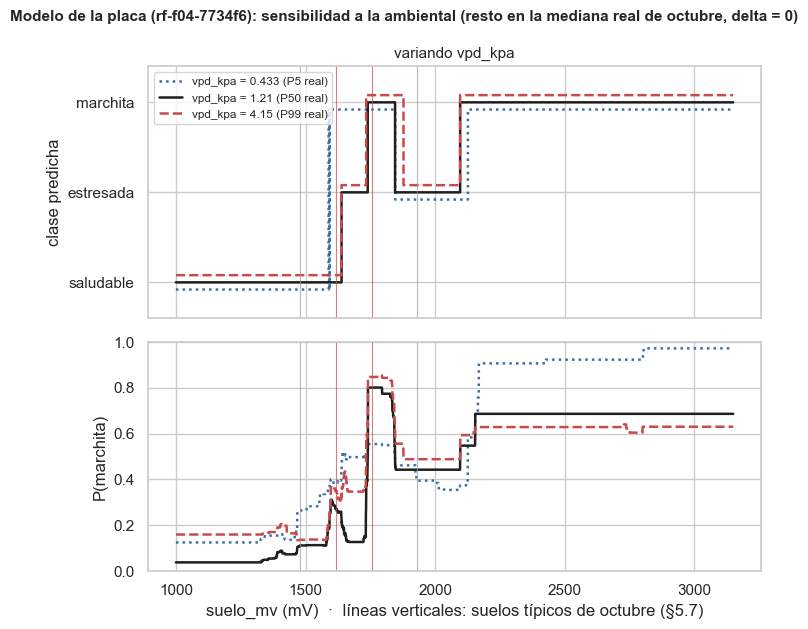

In [26]:
# Figura: clase predicha y P(marchita) contra suelo_mv para tres valores de cada ambiental del modelo
# (percentiles 5, 50 y 99 de lo real); el resto en la mediana real de octubre, delta = 0.
xs_s = np.arange(1000, 3150.25, 0.5).astype(np.float32)
estilos = [("P5", 5, ":", "#3a6ea5"), ("P50", 50, "-", "#1f1f1f"), ("P99", 99, "--", "#c84b4b")]
fig, axes = plt.subplots(2, len(cols_amb), figsize=(7.5 * len(cols_amb), 6.4), sharex=True, squeeze=False,
                         gridspec_kw={"height_ratios": [1.1, 1]})
for j, c in enumerate(cols_amb):
    ax_c, ax_p = axes[0, j], axes[1, j]
    for k, (etq, q, ls, col) in enumerate(estilos):
        v = float(np.percentile(X[es_real, c], q))
        Xg = np.tile(med_oct, (len(xs_s), 1)).astype(np.float32)
        Xg[:, 0] = xs_s
        Xg[:, c] = v
        pr = modelo.predict(Xg)
        pp = modelo.predict_proba(Xg)
        ax_c.step(xs_s, pr + (k - 1) * 0.08, where="post", ls=ls, color=col, lw=1.8,
                  label=f"{FEATURES[c]} = {v:.3g} ({etq} real)")
        ax_p.plot(xs_s, pp[:, 2], ls=ls, color=col, lw=1.8)
    for nombre_s, s in SUELOS_OCT.items():
        for ax in (ax_c, ax_p):
            ax.axvline(s, color="#c84b4b" if "marchita" in nombre_s else "#999999", lw=0.8, alpha=0.7)
    ax_c.set_yticks(CODIGOS, CLASES)
    ax_c.set_ylim(0.6, 3.4)
    ax_c.set_title(f"variando {FEATURES[c]}", fontsize=11)
    ax_c.legend(fontsize=8.5, loc="upper left")
    ax_p.set(ylabel="P(marchita)", ylim=(0, 1), xlabel="suelo_mv (mV)  ·  líneas verticales: suelos típicos de octubre (§5.7)")
axes[0, 0].set_ylabel("clase predicha")
fig.suptitle(f"Modelo de la placa ({version}): sensibilidad a la ambiental (resto en la mediana real de octubre, delta = 0)",
             fontweight="bold", fontsize=11)
fig.tight_layout()
guardar(fig, "modelo_final_sensibilidad.png")
plt.show()


In [27]:
# ¿La luz (u otra ambiental) actúa como proxy de la hora del día? En lo real la clase está atada a la franja
# (V de Cramér 0,47: la marchita observada es sólo de noche).
def cramer_v_(a, b):
    t = pd.crosstab(a, b)
    return np.sqrt(stats.chi2_contingency(t)[0] / (t.values.sum() * (min(t.shape) - 1)))


fr = pd.Series(franja_r)
filas_h = {
    "clase real": cramer_v_(fr, pd.Series(yr_)),
    f"predicción sólo suelo ({version_ss})": cramer_v_(fr, pd.Series(mdl_ss.predict(Xr_))),
    f"predicción criterio original ({version_nb})": cramer_v_(fr, pd.Series(mdl_nb.predict(Xr_))),
    f"predicción nueva ({version})": cramer_v_(fr, pd.Series(modelo.predict(Xr_))),
    "predicción nueva con las ambientales en la mediana": cramer_v_(fr, pd.Series(p_sin)),
}
for c in cols_amb:
    filas_h[f"{FEATURES[c]} (en terciles)"] = cramer_v_(fr, pd.Series(pd.qcut(Xr_[:, c], 3, labels=False, duplicates="drop")))
proxy_hora = pd.Series(filas_h, name="V de Cramér con la franja de 3 h (filas reales)").to_frame()
display(proxy_hora)
# A igual sustrato: ¿el modelo predice más marchita de noche que de día por la ambiental?
for nombre_s in ["marchita ep. 12 (mediana)", "entre saludable y marchita"]:
    s = SUELOS_OCT[nombre_s]
    noc, dia = X[es_real & octubre][noche_r[octubre[es_real]]], X[es_real & octubre][~noche_r[octubre[es_real]]]
    out = {}
    for etq, Xe in [("noche", noc), ("día", dia)]:
        Xe = Xe.copy()
        Xe[:, 0] = s
        Xe[:, 1] = 0.0
        pe = modelo.predict(Xe)
        out[etq] = {CLASES[k - 1]: f"{100 * (pe == k).mean():.0f} %" for k in CODIGOS}
    print(f"suelo_mv fijo en {s:.0f} mV ({nombre_s}), ambiente REAL de octubre:", out)


,V de Cramér con la franja de 3 h (filas reales)
clase real,0.466
predicción sólo suelo (rf-f0-c42286),0.388
predicción criterio original (nb-f02-fa0df4),0.150
predicción nueva (rf-f04-7734f6),0.382
predicción nueva con las ambientales en la mediana,0.389
vpd_kpa (en terciles),0.412


suelo_mv fijo en 1758 mV (marchita ep. 12 (mediana)), ambiente REAL de octubre: {'noche': {'saludable': '0 %', 'estresada': '0 %', 'marchita': '100 %'}, 'día': {'saludable': '0 %', 'estresada': '0 %', 'marchita': '100 %'}}
suelo_mv fijo en 1619 mV (entre saludable y marchita), ambiente REAL de octubre: {'noche': {'saludable': '100 %', 'estresada': '0 %', 'marchita': '0 %'}, 'día': {'saludable': '100 %', 'estresada': '0 %', 'marchita': '0 %'}}


**Lectura de §5.7.**

**Sólo-suelo vs. criterio original vs. nuevo vs. dos umbrales sobre los episodios REALES** (configuraciones fijas, mismos folds):

| exactitud balanceada | todos | sin dudosos | sin el 13 | sin dudosos ni el 13 |
|---|---|---|---|---|
| sólo suelo `rf-f0-c42286`, reales fuera de fold | 0,487 | 0,644 | 0,494 | 0,724 |
| criterio original `nb-f02-fa0df4`, reales fuera de fold | 0,529 | **0,741** | 0,451 | 0,555 |
| **nuevo `rf-f04-7734f6`, reales fuera de fold** | **0,557** | 0,723 | **0,565** | **0,809** |
| dos umbrales | 0,536 | 0,666 | 0,536 | 0,666 |
| sólo suelo, sim → real | 0,557 | 0,717 | 0,563 | 0,797 |
| criterio original, sim → real | 0,523 | **0,730** | 0,445 | 0,531 |
| **nuevo, sim → real** | 0,556 | 0,720 | 0,563 | **0,802** |

- **Recall de marchita real** (todos / sin dudosos): sólo suelo 0,68 / 1,00; criterio original 0,41 / 0,60; nuevo 0,67 / 1,00; dos umbrales 0,67 / 1,00. El ep. 12 lo aciertan todos menos el Naive Bayes.
- **Nuevo vs. sólo suelo.**
  - Puntaje real 0,661 contra 0,623 (+0,038). Gana en el 100 % de las remuestras del bootstrap (desvío de la diferencia 0,019), porque los dos fallan y aciertan casi los mismos episodios y el nuevo acierta más filas del ep. 6.
  - F1 de la serie 0,720 contra 0,715: un empate.
  - Flash 23.730 B contra 24.600 B.
- **Contra el Naive Bayes del criterio original.** Pierde en puntaje (0,661 contra 0,736) porque el NB acierta el ep. 13, pero no pierde la marchita de octubre.

**¿Influye el VPD? Sí, poco, y con respaldo medido débil.**

- **Importancia por permutación** (filas reales):
  - `vpd_kpa`: baja la exactitud balanceada 0,021 ± 0,004 y cambia el 5 % de las predicciones;
  - `suelo_mv`: baja 0,300 y cambia el 51 %;
  - modelo entrenado sólo con simulado: VPD 0,026 y 8 %.
- **VPD en la mediana.**
  - El modelo de la placa cambia la clase de **2,5 % de las filas reales** (33 filas, todas de día): cumple el 1 %.
  - Las 33 filas son de 2 episodios: en el **ep. 6** (septiembre) el VPD ayuda (17 filas: 82 % bien contra 18 % sin VPD); en el **ep. 13** empeora (16 filas: 0 % contra 100 %).
  - El modelo **entrenado sólo con simulado**, que no vio ninguna fila real, cambia 2,9 %: 38 filas del ep. 6, y las 38 pasan de mal a bien. Con VPD bajo (0,4–1,0 kPa) dice `estresada` en vez de `marchita`.
  - Es la única evidencia medida de que la relación aprendida del simulador ("aire más seco → más grave") vale en la planta, y es un solo episodio.
- **Barrido** (`suelo_mv` fijo en valores de octubre, VPD de 0,40 a 4,15 kPa, percentiles 1–99 real):
  - cambia la clase en los 4 suelos;
  - en el rango real de octubre (0,76–1,45 kPa), con 1480 y 1619 mV siempre `saludable` y con 1758 mV siempre `marchita`; entre ~1850 y ~2050 mV alterna `estresada` / `marchita` (RF dentado);
  - con aire seco (VPD ≈ 2) todo lo que está arriba de ~1735 mV pasa a `marchita`;
  - con aire húmedo (VPD ≈ 0,6) la banda marchita de 1740–1845 mV pasa a `estresada`;
  - con VPD muy bajo (< 0,47, frío y húmedo, como el ep. 1 de septiembre) vuelve a `marchita`. Ahí el VPD está confundido con el frío de ese episodio.
- **¿Proxy de la hora?** El VPD sí está asociado a la franja horaria (V de Cramér de sus terciles = 0,41). Pero:
  - la asociación predicción ~ franja es 0,38, igual que el sólo-suelo (0,39) y que el nuevo con el VPD en la mediana (0,39);
  - a sustrato fijo, con el ambiente real de octubre, la predicción es la misma de día y de noche;
  - el ep. 12 (marchita nocturna) se acierta por la sonda, no por el VPD: sacarle el VPD no cambia ninguna de sus filas.

  La luz no entra al modelo.

**Conclusión.** El modelo de la placa usa el VPD, con un efecto chico y verificado sobre lo medido. Ese efecto sale sobre todo de reglas del simulador y lo respalda un solo episodio real (el 6); en el 13 empeora. Con la condición de seguridad, el modelo mantiene la marchita de octubre y queda a la par o algo mejor que el sólo-suelo sobre lo real. Las condiciones que llevaron a elegirlo se fijaron después de ver los resultados (a).


## 6. Control con datos reales

§5.2 ya dio las métricas sobre lo real que usa la selección. Esta sección agrega la **referencia entrenando sólo con reales** y mira por qué falla lo que falla: episodio por episodio, la frontera sobre `suelo_mv`, la deriva de la sonda y la hora del día.

### 6.1 Referencia: sólo con los episodios reales

Mismo protocolo (partición externa e interna por episodio) usando únicamente las filas reales. Reproduce el hallazgo del notebook 02 con los episodios nuevos.

In [28]:
Xr, yr, gr, dr = X[es_real], y[es_real], g[es_real], dudoso[es_real]
print(f"sólo reales: {len(yr):,} filas, {len(np.unique(gr))} episodios "
      f"({pd.Series(yr).map(dict(zip(CODIGOS, CLASES))).groupby(gr).first().value_counts().to_dict()})")
print("(algunos folds internos quedan con una sola clase: esas configuraciones se descartan con NaN)")
solo_reales = {}
for n, (est, grilla) in MODELOS.items():
    solo_reales[n] = evaluar(est, grilla, Xr, yr, gr, tolerante=True)
    for etiqueta, m in [("sólo reales (CV por episodio)", np.ones(len(yr), bool)),
                        ("sólo reales, sin dudosos", ~dr)]:
        p = solo_reales[n]["oof_p"][m]
        tabla_control.loc[(n, etiqueta), :] = pd.Series(
            metricas(yr[m], solo_reales[n]["oof"][m], p if np.isfinite(p).all() else None))

EVALS = EVALS_SEL + ["sólo reales (CV por episodio)", "sólo reales, sin dudosos"]
for m in ["exactitud_bal", "f1_macro", "recall_marchita"]:
    t = tabla_control[m].unstack("evaluación").reindex(index=orden, columns=EVALS)
    t.insert(0, "serie completa (CV, media)", resumen_cv[f"{m} (media)"])
    print(f"\n{m} — filas reales agrupadas (la primera columna es la de §4, para comparar)")
    display(t)
print("\nROC-AUC OvR sobre filas reales (NaN = sin probabilidades o falta una clase):")
display(tabla_control["roc_auc_ovr"].unstack("evaluación").reindex(index=orden, columns=EVALS))

sólo reales: 1,321 filas, 11 episodios ({'estresada': 5, 'marchita': 3, 'saludable': 3})


(algunos folds internos quedan con una sola clase: esas configuraciones se descartan con NaN)



exactitud_bal — filas reales agrupadas (la primera columna es la de §4, para comparar)


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos",sólo reales (CV por episodio),"sólo reales, sin dudosos"
modelo,,,,,,,
Clase mayoritaria,0.333,0.333,0.333,0.333,0.333,0.092,0.232
Umbral único (suelo_mv),0.601,0.534,0.664,0.442,0.664,0.144,0.212
Dos umbrales (suelo_mv),0.751,0.536,0.666,0.536,0.666,0.314,0.495
Regresión logística,0.614,0.452,0.575,0.433,0.549,0.311,0.534
Árbol de decisión,0.728,0.411,0.561,0.532,0.654,0.202,0.371
Random Forest,0.688,0.408,0.546,0.436,0.544,0.089,0.143
Naive Bayes,0.556,0.524,0.731,0.488,0.641,0.219,0.407
k-NN,0.671,0.413,0.537,0.556,0.717,0.104,0.159
SVM RBF,0.600,0.414,0.575,0.415,0.542,0.164,0.238



f1_macro — filas reales agrupadas (la primera columna es la de §4, para comparar)


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos",sólo reales (CV por episodio),"sólo reales, sin dudosos"
modelo,,,,,,,
Clase mayoritaria,0.232,0.162,0.213,0.162,0.213,0.072,0.106
Umbral único (suelo_mv),0.523,0.388,0.550,0.351,0.557,0.130,0.225
Dos umbrales (suelo_mv),0.749,0.389,0.551,0.389,0.551,0.320,0.479
Regresión logística,0.606,0.374,0.564,0.365,0.539,0.313,0.488
Árbol de decisión,0.706,0.328,0.502,0.386,0.542,0.195,0.299
Random Forest,0.664,0.329,0.483,0.323,0.462,0.082,0.115
Naive Bayes,0.534,0.476,0.731,0.416,0.634,0.205,0.335
k-NN,0.652,0.332,0.481,0.436,0.654,0.089,0.141
SVM RBF,0.601,0.370,0.571,0.331,0.499,0.144,0.224



recall_marchita — filas reales agrupadas (la primera columna es la de §4, para comparar)


evaluación,"serie completa (CV, media)",reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos",sólo reales (CV por episodio),"sólo reales, sin dudosos"
modelo,,,,,,,
Clase mayoritaria,0.000,0.000,0.000,0.000,0.000,0.000,0.000
Umbral único (suelo_mv),0.823,0.674,1.000,0.000,0.000,0.000,0.000
Dos umbrales (suelo_mv),0.811,0.674,1.000,0.674,1.000,0.407,0.604
Regresión logística,0.422,0.422,0.604,0.422,0.604,0.236,0.350
Árbol de decisión,0.775,0.652,0.968,0.696,1.000,0.000,0.000
Random Forest,0.797,0.674,1.000,0.593,0.866,0.006,0.009
Naive Bayes,0.415,0.407,0.604,0.407,0.604,0.000,0.000
k-NN,0.687,0.621,0.922,0.671,0.995,0.000,0.000
SVM RBF,0.487,0.432,0.641,0.575,0.829,0.000,0.000



ROC-AUC OvR sobre filas reales (NaN = sin probabilidades o falta una clase):


evaluación,reales fuera de fold,"reales fuera de fold, sin dudosos",sim → real,"sim → real, sin dudosos",sólo reales (CV por episodio),"sólo reales, sin dudosos"
modelo,,,,,,
Clase mayoritaria,0.500,0.500,0.500,0.500,0.302,0.424
Umbral único (suelo_mv),0.504,0.802,0.651,0.877,0.241,0.508
Dos umbrales (suelo_mv),NaN,NaN,NaN,NaN,NaN,NaN
Regresión logística,0.577,0.853,0.626,0.828,0.453,0.737
Árbol de decisión,0.588,0.750,0.652,0.872,0.273,0.533
Random Forest,0.589,0.812,0.625,0.795,0.271,0.412
Naive Bayes,0.525,0.850,0.603,0.812,0.400,0.637
k-NN,0.662,0.764,0.685,0.856,0.240,0.344
SVM RBF,NaN,NaN,NaN,NaN,NaN,NaN


figura: docs/entrega2/fig/control_reales.png


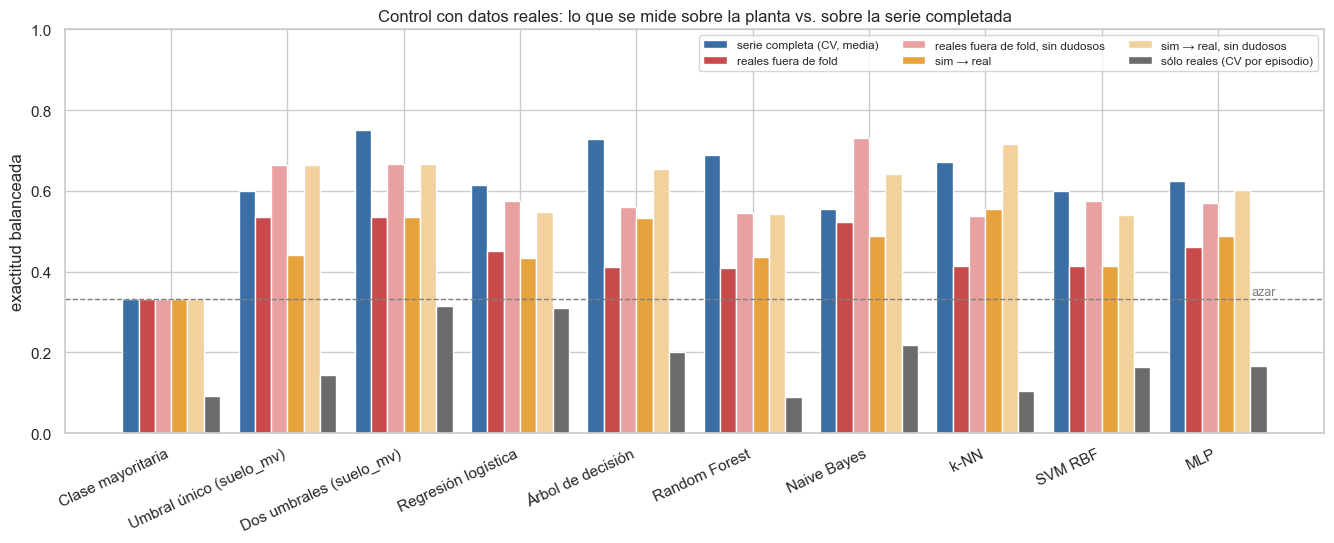

In [29]:
fig, ax = plt.subplots(figsize=(13.5, 5.6))
cols = ["serie completa (CV, media)", "reales fuera de fold", "reales fuera de fold, sin dudosos",
        "sim → real", "sim → real, sin dudosos", "sólo reales (CV por episodio)"]
t = tabla_control["exactitud_bal"].unstack("evaluación").reindex(index=orden)
t.insert(0, "serie completa (CV, media)", resumen_cv["exactitud_bal (media)"])
t = t[cols]
paleta = ["#3a6ea5", "#c84b4b", "#e8a0a0", "#e6a23c", "#f3d19c", "#6b6b6b"]
ancho = 0.14
for i, (c, col) in enumerate(zip(cols, paleta)):
    ax.bar(np.arange(len(orden)) + (i - 2.5) * ancho, t[c], ancho, label=c, color=col)
ax.axhline(1 / 3, ls="--", color="gray", lw=1)
ax.text(len(orden) - 0.5, 1 / 3 + 0.01, "azar", color="gray", fontsize=9, ha="right")
ax.set_xticks(np.arange(len(orden)), orden, rotation=25, ha="right")
ax.set(ylabel="exactitud balanceada", ylim=(0, 1),
       title="Control con datos reales: lo que se mide sobre la planta vs. sobre la serie completada")
ax.legend(fontsize=8.5, ncol=3, loc="upper right")
fig.tight_layout()
guardar(fig, "control_reales.png")
plt.show()

### 6.2 Sensibilidad al episodio 13 (el conflicto del 19/10)

El 19/10 hay dos observaciones con el botón a pocas horas de distancia y con la sonda casi en el mismo valor:

- el **ep. 12**: `marchita`, de noche, con ~1756 mV;
- el **ep. 13**: `estresada`, a la mañana siguiente, con ~1796 mV en la pulsación. La mediana del episodio es más alta porque después de la pulsación siguió 11–12 h propagado mientras el sustrato se secaba, hasta el riego.

Ninguna regla monótona sobre `suelo_mv` respeta las dos. El relleno v2 se calibró **creyéndole al 12** (umbral de marchita de octubre ~1745 mV; ver `data/sintetico/README.md`). Por eso no se marca dudoso al 13: sería circular, porque se descartaría justamente el episodio que contradice la calibración. En cambio se reporta la sensibilidad: las mismas métricas sobre lo real, con todos, sin dudosos, sin el 13 y sin dudosos ni el 13. **El criterio de selección de §5.3 no cambia**: usa "sin dudosos".

In [30]:
es_13 = (g == 13)
mascaras = {"todos": es_real, "sin dudosos": sin_dud, "sin el 13": es_real & ~es_13,
            "sin dudosos ni el 13": sin_dud & ~es_13}
filas_s = {}
for n in orden:
    for nombre_m, m in mascaras.items():
        filas_s[(n, nombre_m)] = {
            "exactitud_bal reales fuera de fold": balanced_accuracy_score(y[m], resultados[n]["oof"][m]),
            "F1 macro reales fuera de fold": f1m(y[m], resultados[n]["oof"][m]),
            "exactitud_bal sim → real": balanced_accuracy_score(y[m], pred_sim2real[n][m]),
            "F1 macro sim → real": f1m(y[m], pred_sim2real[n][m]),
            "recall marchita sim → real": recall_marchita(y[m], pred_sim2real[n][m]),
        }
sensibilidad = pd.DataFrame(filas_s).T
sensibilidad.index.names = ["modelo", "episodios reales"]
for col in ["exactitud_bal reales fuera de fold", "exactitud_bal sim → real", "F1 macro sim → real"]:
    print(f"\n{col}")
    display(sensibilidad[col].unstack("episodios reales").reindex(index=orden, columns=list(mascaras)))


exactitud_bal reales fuera de fold


episodios reales,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.333,0.333,0.333,0.333
Umbral único (suelo_mv),0.534,0.664,0.534,0.664
Dos umbrales (suelo_mv),0.536,0.666,0.536,0.666
Regresión logística,0.452,0.575,0.424,0.503
Árbol de decisión,0.411,0.561,0.418,0.641
Random Forest,0.408,0.546,0.412,0.589
Naive Bayes,0.524,0.731,0.445,0.532
k-NN,0.413,0.537,0.410,0.539
SVM RBF,0.414,0.575,0.381,0.529



exactitud_bal sim → real


episodios reales,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.333,0.333,0.333,0.333
Umbral único (suelo_mv),0.442,0.664,0.379,0.664
Dos umbrales (suelo_mv),0.536,0.666,0.536,0.666
Regresión logística,0.433,0.549,0.413,0.509
Árbol de decisión,0.532,0.654,0.532,0.654
Random Forest,0.436,0.544,0.436,0.544
Naive Bayes,0.488,0.641,0.444,0.530
k-NN,0.556,0.717,0.562,0.795
SVM RBF,0.415,0.542,0.399,0.507



F1 macro sim → real


episodios reales,todos,sin dudosos,sin el 13,sin dudosos ni el 13
modelo,,,,
Clase mayoritaria,0.162,0.213,0.175,0.240
Umbral único (suelo_mv),0.351,0.557,0.285,0.484
Dos umbrales (suelo_mv),0.389,0.551,0.427,0.608
Regresión logística,0.365,0.539,0.360,0.524
Árbol de decisión,0.386,0.542,0.422,0.596
Random Forest,0.323,0.462,0.350,0.502
Naive Bayes,0.416,0.634,0.366,0.530
k-NN,0.436,0.654,0.489,0.812
SVM RBF,0.331,0.499,0.324,0.475


### 6.3 El modelo final, episodio por episodio (reales)

Proporción de filas de cada episodio real que el modelo final asigna a cada clase (entrenado con toda la serie, como va a la placa) y el acierto con las tres evaluaciones. Agregados por episodio: no se listan filas.

In [31]:
p_final_todo = modelo.predict(X)
p_final_sim = clone(modelo_final()).fit(X[solo_sim], y[solo_sim]).predict(X)
filas_tab = []
for e, d in df[es_real].groupby("episodio_id"):
    idx = d.index.to_numpy()
    fila = {"episodio": e, "clase": d.clase.iloc[0], "dudoso": bool(d.dudoso.iloc[0]), "filas": len(d),
            "suelo_mv_mediana": d.suelo_mv.median()}
    for c, nombre in zip(CODIGOS, CLASES):
        fila[f"final→{nombre[:5]}"] = (p_final_todo[idx] == c).mean()
    fila["acierto final (train)"] = (p_final_todo[idx] == y[idx]).mean()
    fila["acierto fuera de fold"] = (oof_fija[idx] == y[idx]).mean()
    fila["acierto sim→real"] = (p_final_sim[idx] == y[idx]).mean()
    filas_tab.append(fila)
por_ep = pd.DataFrame(filas_tab).set_index("episodio")
display(por_ep)
ok = por_ep["acierto fuera de fold"] > 0.5
print(f"episodios reales con más de la mitad de las filas bien (fuera de fold): {ok.sum()} de {len(por_ep)}; "
      f"sin dudosos: {ok[~por_ep.dudoso].sum()} de {(~por_ep.dudoso).sum()}")
ok_s = por_ep["acierto sim→real"] > 0.5
print(f"ídem entrenando sólo con simulado: {ok_s.sum()} de {len(por_ep)}; "
      f"sin dudosos: {ok_s[~por_ep.dudoso].sum()} de {(~por_ep.dudoso).sum()}")

,clase,dudoso,filas,suelo_mv_mediana,final→salud,final→estre,final→march,acierto final (train),acierto fuera de fold,acierto sim→real
episodio,,,,,,,,,,
1,marchita,False,131,"2,832.000",0.000,0.000,1.000,1.000,1.000,1.000
3,estresada,False,23,"2,769.500",0.000,0.000,1.000,0.000,0.000,0.000
6,estresada,False,69,"2,050.000",0.000,0.913,0.087,0.913,0.580,0.551
8,marchita,True,105,"1,512.000",1.000,0.000,0.000,0.000,0.000,0.000
9,estresada,True,51,"1,454.000",1.000,0.000,0.000,0.000,0.000,0.000
10,saludable,False,137,"1,504.000",0.978,0.022,0.000,0.978,0.978,0.978
11,saludable,True,27,"1,785.500",0.000,0.074,0.926,0.000,0.000,0.000
12,marchita,False,86,"1,758.000",0.000,0.000,1.000,1.000,1.000,1.000
13,estresada,False,136,"1,929.750",0.000,0.743,0.257,0.743,0.000,0.000


episodios reales con más de la mitad de las filas bien (fuera de fold): 5 de 11; sin dudosos: 5 de 7
ídem entrenando sólo con simulado: 5 de 11; sin dudosos: 5 de 7


### 6.4 La frontera sobre `suelo_mv` y la deriva de la sonda

Distribución de `suelo_mv` por clase en el relleno y en lo real, con los cortes del modelo final. El modelo final usa además `vpd_kpa`; acá se muestra su frontera sobre `suelo_mv` con el VPD en la mediana de la serie (~1,2 kPa, el aire de octubre). Cómo la corre el VPD está en §5.7.

figura: docs/entrega2/fig/fronteras_suelo_mv.png


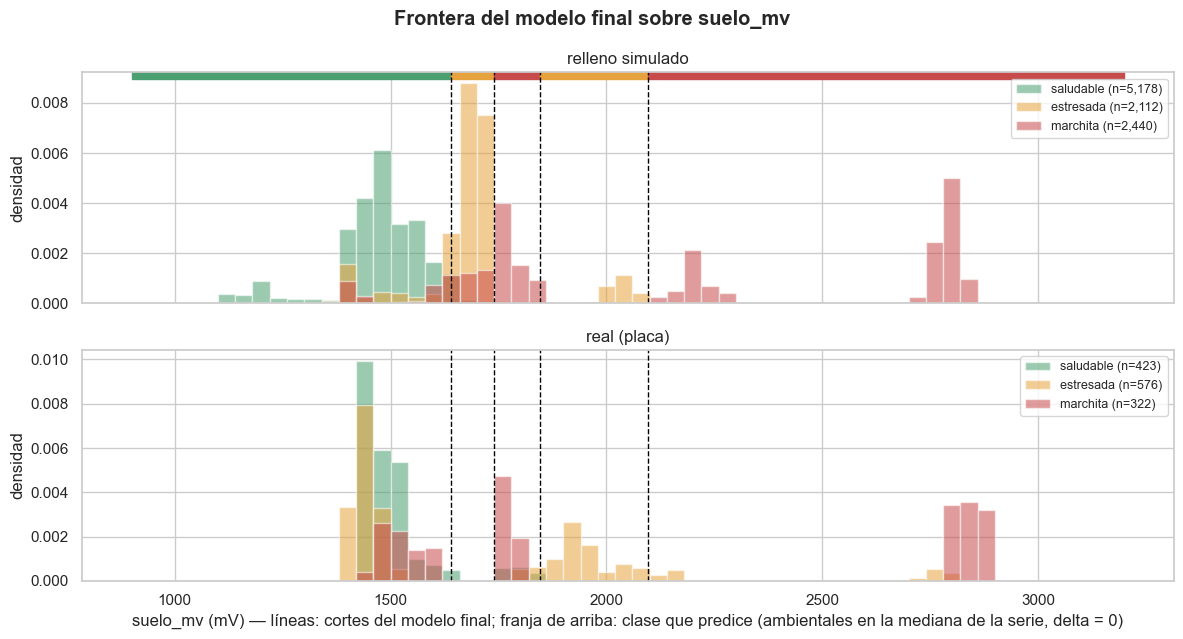

cambios de clase sobre suelo_mv (mV): [1639.0, 1740.0, 1845.5, 2096.25]


In [32]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
bins = np.arange(900, 3200, 40)
for ax, f in zip(axes, ["simulada_relleno", "real"]):
    d = df[df.fuente == f]
    for c in CLASES:
        v = d.loc[d.clase == c, "suelo_mv"]
        if len(v):
            ax.hist(v, bins=bins, density=True, alpha=0.55, color=COLORES[c], label=f"{c} (n={len(v):,})")
    for u in umbrales_final:
        ax.axvline(u, color="black", ls="--", lw=1)
    ax.set_ylabel("densidad")
    ax.set_title(FUENTES[f])
    ax.legend(fontsize=9, loc="upper right")
for t in tramos:
    axes[0].axvspan(xs[t[0]], xs[t[-1]], ymin=0.97, ymax=1.0, color=COLORES[CLASES[pred_grid[t[0]] - 1]])
axes[1].set_xlabel("suelo_mv (mV) — líneas: cortes del modelo final; franja de arriba: clase que predice "
                   "(ambientales en la mediana de la serie, delta = 0)")
fig.suptitle("Frontera del modelo final sobre suelo_mv", fontweight="bold")
fig.tight_layout()
guardar(fig, "fronteras_suelo_mv.png")
plt.show()
print("cambios de clase sobre suelo_mv (mV):", [round(u, 2) for u in umbrales_final])

In [33]:
# Deriva de la sonda en lo real: el mismo estado de la planta, otra lectura según el mes.
r = df[es_real].assign(periodo=np.where(df.loc[es_real, "ts"] < "2026-10-01", "septiembre", "octubre"))
display(r.groupby(["clase", "periodo"]).agg(episodios=("episodio_id", "nunique"), filas=("ts", "size"),
                                            suelo_mv_mediana=("suelo_mv", "median"))
        .unstack("periodo").reindex(CLASES))
s = df[~es_real].assign(periodo=np.where(df.loc[~es_real, "ts"] < "2026-10-01", "septiembre", "octubre"))
print("Relleno simulado, mediana de suelo_mv por clase y mes:")
display(s.groupby(["clase", "periodo"]).suelo_mv.median().unstack("periodo").reindex(CLASES))
print(f"máximo de suelo_mv real en octubre (serie filtrada): {r[r.periodo == 'octubre'].suelo_mv.max():.0f} mV · "
      f"filas simuladas de octubre por encima: {(s[s.periodo == 'octubre'].suelo_mv > r[r.periodo == 'octubre'].suelo_mv.max()).mean():.1%}")

episodios              filas            suelo_mv_mediana           
periodo     octubre septiembre octubre septiembre          octubre septiembre
clase                                                                        
saludable     3.000        NaN 423.000        NaN        1,480.000        NaN
estresada     3.000      2.000 484.000     92.000        1,455.250  2,064.000
marchita      2.000      1.000 191.000    131.000        1,592.500  2,832.000

Relleno simulado, mediana de suelo_mv por clase y mes:


periodo,octubre,septiembre
clase,,
saludable,"1,488.500","1,456.000"
estresada,"1,691.000","1,674.000"
marchita,"1,709.250","2,272.000"


máximo de suelo_mv real en octubre (serie filtrada): 1954 mV · filas simuladas de octubre por encima: 0.0%


### 6.5 ¿La clase sigue a la hora del día?

La hora no es feature, pero si la clase está atada al reloj, la luz y la temperatura pueden colarla. Se mide la asociación entre la franja horaria (8 franjas de 3 h, hora local UTC−3) y la clase con la V de Cramér: 0 = independientes, 1 = la franja determina la clase.

V de Cramér franja horaria × clase:
  reales            0.47
  relleno simulado  0.10
  predicción del modelo final sobre los reales: 0.38
  predicción del modelo sólo-suelo (rf-f0-c42286) sobre los reales: 0.39
Mediana de luz_mv por clase:


fuente,real,simulada_relleno
clase,,
saludable,"1,418.500","1,141.000"
estresada,"1,624.750","1,010.250"
marchita,142.000,"1,197.000"


figura: docs/entrega2/fig/clase_por_hora.png


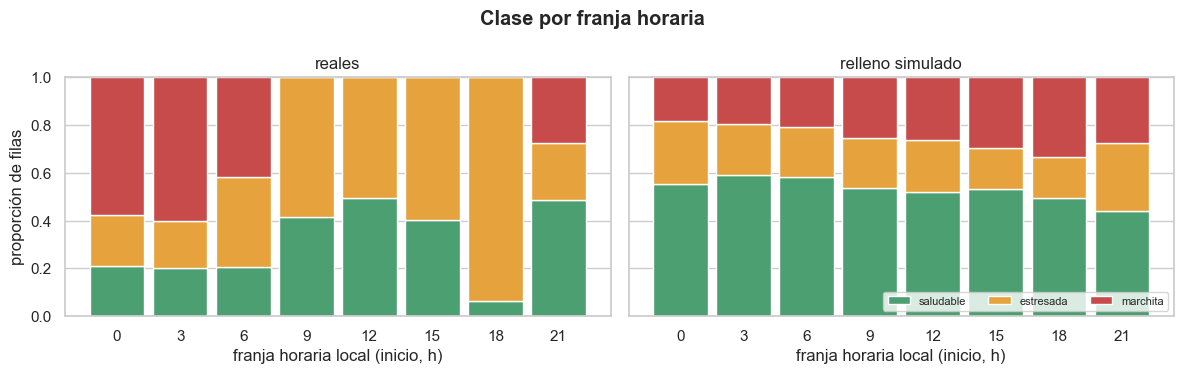

In [34]:
def cramer_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(t)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))


franja = ((df.ts - pd.Timedelta(hours=3)).dt.hour // 3) * 3
print("V de Cramér franja horaria × clase:")
for etiqueta, m in [("reales", es_real), ("relleno simulado", ~es_real)]:
    print(f"  {etiqueta:<17} {cramer_v(franja[m], df.clase[m]):.2f}")
print(f"  predicción del modelo final sobre los reales: {cramer_v(franja[es_real], pd.Series(p_final_todo[es_real], index=franja[es_real].index)):.2f}")
print(f"  predicción del modelo sólo-suelo ({version_ss}) sobre los reales: "
      f"{cramer_v(franja[es_real], pd.Series(mdl_ss.predict(X[es_real]), index=franja[es_real].index)):.2f}")
print("Mediana de luz_mv por clase:")
display(df.groupby(["clase", "fuente"]).luz_mv.median().unstack("fuente").reindex(CLASES))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, (etiqueta, m) in zip(axes, [("reales", es_real), ("relleno simulado", ~es_real)]):
    p = pd.crosstab(franja[m], df.clase[m], normalize="index").reindex(columns=CLASES).fillna(0)
    base = np.zeros(len(p))
    for c in CLASES:
        ax.bar(p.index, p[c], 2.6, bottom=base, color=COLORES[c], label=c)
        base += p[c].values
    ax.set(title=etiqueta, xlabel="franja horaria local (inicio, h)", xticks=range(0, 24, 3))
axes[0].set_ylabel("proporción de filas")
axes[1].legend(ncol=3, fontsize=8, loc="lower right")
fig.suptitle("Clase por franja horaria", fontweight="bold")
fig.tight_layout()
guardar(fig, "clase_por_hora.png")
plt.show()

**Lectura del control con datos reales** (búsqueda anidada por tipo, espacio restringido).

- **El número de la serie completa no predice el de lo real.**
  - Naive Bayes es de los peores en la serie (F1 0,534) y el mejor en lo real sin dudosos (0,731 fuera de fold).
  - El RF con búsqueda anidada queda último en lo real (0,546). La búsqueda interna elige por F1 de la serie, no por lo real.
  - La configuración fija elegida en §5.6 da 0,723.
  - Con 7 episodios reales no dudosos, el orden lo deciden 1 o 2 episodios.
- **Entrenando sólo con reales, nada generaliza.** El mejor es la regresión logística con 0,311 / 0,534. Es el hallazgo del notebook 02.

**El conflicto del 19/10 (ep. 12 vs. ep. 13).**

- Las dos pulsaciones están a 40 mV: la marchita del 12, de noche, con 1756 mV, y la estresada del 13, a la mañana, con 1796 mV. Ningún modelo monótono en la sonda acierta las dos.
- La condición de seguridad le da prioridad al 12 (no perder una marchita).
- El modelo final acierta el 12 y falla el 13 fuera de fold (0 %). Sin el 13 su exactitud balanceada real sube a 0,809 (sin dudosos).
- **Sólo las fotos de la ESP32-CAM del 19/10 pueden resolverlo.**

**Por episodio**, el modelo final falla en:

- las etiquetas dudosas (8, 9, 11, 14);
- el ep. 3 (estresada sobre el radiador, sustrato de marchita);
- el ep. 13.

Acierta más de la mitad en 5 de los 7 no dudosos, fuera de fold y en sim → real.

**La hora.**

- La clase real está atada a la franja horaria (V de Cramér 0,47; marchita sólo de noche); la del relleno v2 casi nada (0,10).
- El modelo final no usa la luz. La asociación de su predicción con la franja (0,38) es la del sólo-suelo y llega por el sustrato: con el VPD en la mediana da lo mismo.


### 6.6 Análisis secundario: binario *requiere cuidado*

`estresada` ∪ `marchita` contra `saludable`. No es el modelo de la placa (que es de 3 clases): sirve para ver si al menos la pregunta gruesa "¿hay que hacer algo?" se puede contestar. Mismo protocolo por episodio, con los baselines y tres candidatos baratos de exportar (árbol, regresión logística, Naive Bayes), en la serie completa, en las filas reales fuera de fold y en la transferencia simulado → real.

In [35]:
yb = (y >= 2).astype(int)        # 1 = requiere cuidado


def ajustar_bin(est, grilla, idx):
    if grilla:
        return busqueda(est, grilla).fit(X[idx], yb[idx], groups=g[idx]).best_estimator_
    return clone(est).fit(X[idx], yb[idx])


def evaluar_binario(est, grilla):
    folds = []
    oof = np.zeros(len(yb), int)
    for tr, te in particion_externa().split(X, y, g):   # mismos folds que §4 (estratificados en 3 clases)
        mdl = ajustar_bin(est, grilla, tr)
        oof[te] = mdl.predict(X[te])
        pp = mdl.predict_proba(X[te])[:, list(mdl.classes_).index(1)] if hasattr(mdl, "predict_proba") else None
        folds.append({"exactitud_bal": balanced_accuracy_score(yb[te], oof[te]),
                      "f1_cuidado": f1_score(yb[te], oof[te], zero_division=0),
                      "recall_cuidado": recall_score(yb[te], oof[te], zero_division=0),
                      "roc_auc": roc_auc_score(yb[te], pp) if pp is not None else np.nan})
    return pd.DataFrame(folds), oof


filas_b = {}
for n in ["Clase mayoritaria", "Umbral único (suelo_mv)", "Árbol de decisión", "Regresión logística", "Naive Bayes"]:
    est, grilla = MODELOS[n]
    f, oof_b = evaluar_binario(est, grilla)
    s2r = ajustar_bin(est, grilla, np.flatnonzero(solo_sim)).predict(X)
    fila = {m: f"{f[m].mean():.3f} ± {f[m].std(ddof=0):.3f}" if f[m].notna().all() else "n/d" for m in f}
    for etiqueta, pred in [("reales fuera de fold", oof_b), ("sim → real", s2r)]:
        fila[f"exactitud_bal {etiqueta} (sin dudosos)"] = balanced_accuracy_score(yb[sin_dud], pred[sin_dud])
        fila[f"recall_cuidado {etiqueta} (sin dudosos)"] = recall_score(yb[sin_dud], pred[sin_dud], zero_division=0)
    filas_b[n] = fila
tabla_binaria = pd.DataFrame(filas_b).T
display(tabla_binaria)

,exactitud_bal,f1_cuidado,recall_cuidado,roc_auc,exactitud_bal reales fuera de fold (sin dudosos),recall_cuidado reales fuera de fold (sin dudosos),exactitud_bal sim → real (sin dudosos),recall_cuidado sim → real (sin dudosos)
Clase mayoritaria,0.500 ± 0.000,0.061 ± 0.122,0.200 ± 0.400,0.500 ± 0.000,0.097,0.193,0.500,0.000
Umbral único (suelo_mv),0.879 ± 0.073,0.859 ± 0.093,0.779 ± 0.139,0.879 ± 0.073,0.996,1.000,0.996,1.000
Árbol de decisión,0.845 ± 0.076,0.785 ± 0.163,0.826 ± 0.134,0.878 ± 0.100,0.784,1.000,0.981,1.000
Regresión logística,0.873 ± 0.056,0.845 ± 0.093,0.832 ± 0.124,0.899 ± 0.065,0.966,1.000,0.962,1.000
Naive Bayes,0.823 ± 0.126,0.811 ± 0.117,0.737 ± 0.099,0.850 ± 0.135,1.000,1.000,1.000,1.000


**Binario.** La pregunta gruesa "¿hay que hacer algo?" se contesta bastante mejor que la de 3 clases.

- Un solo umbral sobre `suelo_mv` da 0,879 ± 0,073 en la serie completa y ~1,0 sobre los reales sin dudosos (fuera de fold y sim → real). Los candidatos usan acá el espacio restringido (suelo + ambiental) y no mejoran al umbral.
- Separar *seco* de *no seco* es lo que la sonda resuelve con confianza. Lo difícil es separar `estresada` de `marchita`, justo lo que la deriva de la sonda y el conflicto del 19/10 borran.
- Ojo: son 7 episodios reales, con los saludables todos en ~1450–1500 mV.

### 6.7 Prueba con datos nuevos de Railway (posteriores al entrenamiento)

El modelo se entrenó con el snapshot del 21/10 (`SNAPSHOT_VIGENTE`). La placa siguió mandando a Railway, así que el snapshot del 22/10 (`data/mediciones_raw_2026-10-22.csv`, bajado de `GET /api/v1/mediciones.csv`) trae muestras **reales que el modelo nunca vio**. Se pasan por el mismo `serie_maceta01` (remuestreo, features, filtros de calidad) y se predicen con el modelo final y con el mismo Random Forest entrenado sólo con las filas reales.

Límite: esas filas no tienen observación manual. La placa las mandó con `saludable` **propagada** de la pulsación del 20/10 (ep. 15) y nadie miró la planta, así que es una prueba de estabilidad sobre un tramo `saludable`, no una evaluación de las tres clases. No se suman al entrenamiento.

filas nuevas (5 min): 184, del 21/10 21:25 al 22/10 12:40 UTC; sin episodio asignado
etiqueta que mandó la placa (filas crudas a 30 s): {('saludable', 'propagada'): 1829}


,marchita,saludable
modelo final (real + simulado),0,184
"mismo RF, sólo reales",70,114


,count,mean,std,min,25%,50%,75%,max
suelo_mv,184.000,"1,504.800",4.470,"1,496.000","1,504.000","1,504.000","1,504.500","1,520.000"
vpd_kpa,184.000,1.150,0.150,0.760,1.040,1.200,1.270,1.360
temp_c,184.000,20.750,0.650,19.400,20.200,21.000,21.000,22.200
hum_aire_pct,184.000,53.030,4.550,45.000,49.000,52.000,56.000,67.000
luz_mv,184.000,844.490,854.770,142.000,142.000,142.000,"1,737.500","2,521.500"


figura: docs/entrega2/fig/prueba_railway_nuevos.png

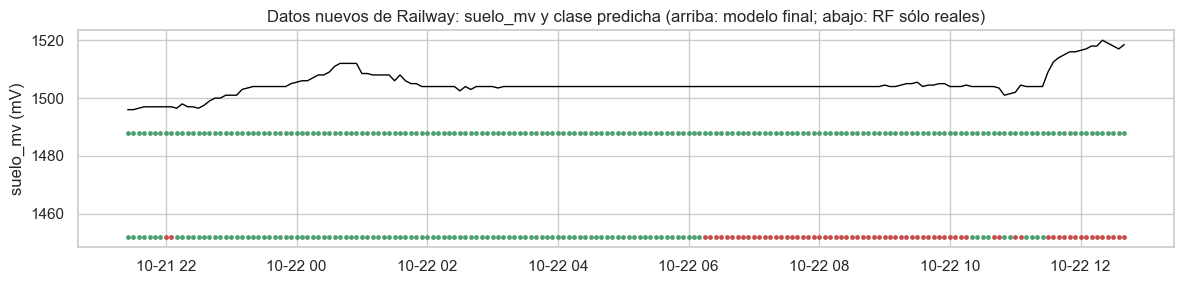

In [36]:
SNAPSHOT_NUEVO = RAIZ / "data" / "mediciones_raw_2026-10-22.csv"
corte = df.loc[es_real, "ts"].max()          # última fila real que vio el entrenamiento
nuevo = serie_maceta01(snapshot=SNAPSHOT_NUEVO, incluir_complemento=False, filtrado=False)
nuevo = nuevo[(nuevo.ts > corte) & nuevo.valido & ~nuevo.post_boot & ~nuevo.suelo_saturado]
Xn = matriz_X(nuevo)
print(f"filas nuevas (5 min): {len(nuevo)}, del {nuevo.ts.min():%d/%m %H:%M} al {nuevo.ts.max():%d/%m %H:%M} UTC; "
      f"sin episodio asignado")
crudo_nuevo = pd.read_csv(SNAPSHOT_NUEVO)
crudo_nuevo = crudo_nuevo[pd.to_datetime(crudo_nuevo.ts_servidor, format="ISO8601", utc=True) > corte]
print("etiqueta que mandó la placa (filas crudas a 30 s):",
      crudo_nuevo.groupby(["condicion_etiqueta", "etiqueta_origen"]).size().to_dict())

m_final = modelo_final().fit(X, y)                       # el mismo que exporta exportar_c
m_solo_reales = modelo_final().fit(X[es_real], y[es_real])
assert version_modelo(m_final) == version
pred_nuevo = pd.DataFrame({"modelo final (real + simulado)": m_final.predict(Xn),
                           "mismo RF, sólo reales": m_solo_reales.predict(Xn)}).replace(dict(enumerate(CLASES, 1)))
display(pred_nuevo.apply(lambda s: s.value_counts()).fillna(0).astype(int).T)
display(nuevo[["suelo_mv", "vpd_kpa", "temp_c", "hum_aire_pct", "luz_mv"]].describe().round(2).T)

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(nuevo.ts, nuevo.suelo_mv, color="black", lw=1)
for clase_n in CLASES:
    for col_n, y_n in [("modelo final (real + simulado)", 0.0), ("mismo RF, sólo reales", 0.06)]:
        mask_n = (pred_nuevo[col_n] == clase_n).to_numpy()
        ax.scatter(nuevo.ts[mask_n], np.full(mask_n.sum(), nuevo.suelo_mv.min() - 8 - 600 * y_n), s=6,
                   color=COLORES[clase_n])
ax.set_ylabel("suelo_mv (mV)")
ax.set_title("Datos nuevos de Railway: suelo_mv y clase predicha (arriba: modelo final; abajo: RF sólo reales)")
fig.tight_layout()
guardar(fig, "prueba_railway_nuevos.png")
plt.show()

## 7. Resumen de números y discusión

La celda siguiente junta los números clave **calculados en esta ejecución** y escribe todas las tablas en `docs/entrega2/tablas_03_modelos.md` (generado, no editar): así, si se reemplaza el relleno y se re-ejecuta el notebook, el resumen y las tablas se actualizan solos.

In [37]:
def fmt(v):
    return f"{v:.3f}" if isinstance(v, (float, np.floating)) and np.isfinite(v) else str(v)


clave = {
    "relleno (archivo, fecha)": RELLENO_INFO,
    "filas / episodios (serie)": f"{len(df):,} / {df.episodio_id.nunique()}",
    "filas / episodios reales": f"{es_real.sum():,} / {df[es_real].episodio_id.nunique()}",
    "episodios dudosos": str(sorted(EPISODIOS_DUDOSOS)),
    "fuga: RF 7 features, aleatoria vs por episodio (serie)": " vs ".join(fuga.iloc[0].values),
    "fuga: ídem sólo reales": " vs ".join(fuga.iloc[1].values),
    "criterio original en el espacio restringido (sin seguridad)": f"{tipo_original} {describir(config_original)}",
    "elegido con la condición de seguridad": f"{final_tipo} {describir(final_params)}",
    "config final": f"{CONFIG_FINAL['tipo']} {describir(CONFIG_FINAL['params'])}",
    "coincide con CONFIG_FINAL": coincide,
    "versión": version,
    "header al día": version == en_header,
    "F1 macro serie, elegido (búsqueda anidada)": tabla_cv.loc[elegido, "f1_macro"],
    "F1 macro serie, dos umbrales": tabla_cv.loc["Dos umbrales (suelo_mv)", "f1_macro"],
    "puntaje real elegido / dos umbrales / umbral único / mayoritaria":
        " / ".join(fmt(sel.loc[n, "puntaje_real"]) for n in RIVALES),
    "desvío bootstrap del puntaje real": fmt(desvio_real),
    "exactitud bal. reales fuera de fold (con / sin dudosos), elegido":
        f"{fmt(tabla_control.loc[(elegido, 'reales fuera de fold'), 'exactitud_bal'])} / "
        f"{fmt(tabla_control.loc[(elegido, 'reales fuera de fold, sin dudosos'), 'exactitud_bal'])}",
    "exactitud bal. sim → real (con / sin dudosos), elegido":
        f"{fmt(tabla_control.loc[(elegido, 'sim → real'), 'exactitud_bal'])} / "
        f"{fmt(tabla_control.loc[(elegido, 'sim → real, sin dudosos'), 'exactitud_bal'])}",
    "exactitud bal. sólo reales (con / sin dudosos), elegido":
        f"{fmt(tabla_control.loc[(elegido, 'sólo reales (CV por episodio)'), 'exactitud_bal'])} / "
        f"{fmt(tabla_control.loc[(elegido, 'sólo reales, sin dudosos'), 'exactitud_bal'])}",
    "exactitud bal. sim → real (todos / sin dud. / sin 13 / sin dud. ni 13), elegido":
        " / ".join(fmt(sensibilidad.loc[(elegido, k), "exactitud_bal sim → real"]) for k in mascaras),
    "exactitud bal. reales fuera de fold (todos / sin dud. / sin 13 / sin dud. ni 13), elegido":
        " / ".join(fmt(sensibilidad.loc[(elegido, k), "exactitud_bal reales fuera de fold"]) for k in mascaras),
    "costo elegido": str(costo_esp32(modelo)),
    "restricción de diseño": "suelo_mv + al menos una ambiental en todos los candidatos con selección",
    "features del modelo final": ", ".join(FEATURES[c] for c in modelo.named_steps["sel"].columnas),
    "% filas reales que cambian con la ambiental en la mediana (final / sim → real)":
        " / ".join(fmt(cambio_mediana.loc[(k, FEATURES[cols_amb[0]], "mediana de la serie"), "% filas reales que cambian"])
                   for k in ["final", "sim → real"]),
    "configuraciones exploradas / que pasan costo + influencia + seguridad":
        f"{len(explor)} / {int(explor.pasa_filtros.sum())}",
    "puntaje real config. fija: sólo suelo / criterio original / nuevo / dos umbrales":
        " / ".join(fmt(v) for v in resumen_cmp["puntaje real (config. fija)"]),
    "exactitud bal. reales fuera de fold (todos / sin dud. / sin 13 / sin dud. ni 13), sólo suelo":
        " / ".join(fmt(comparacion.loc[(k_ss, "reales fuera de fold", k), "exactitud_bal"]) for k in MASCARAS),
    "exactitud bal. reales fuera de fold (todos / sin dud. / sin 13 / sin dud. ni 13), nuevo":
        " / ".join(fmt(comparacion.loc[(k_nv, "reales fuera de fold", k), "exactitud_bal"]) for k in MASCARAS),
    "exactitud bal. sim → real (todos / sin dud. / sin 13 / sin dud. ni 13), sólo suelo":
        " / ".join(fmt(comparacion.loc[(k_ss, "sim → real", k), "exactitud_bal"]) for k in MASCARAS),
    "exactitud bal. sim → real (todos / sin dud. / sin 13 / sin dud. ni 13), nuevo":
        " / ".join(fmt(comparacion.loc[(k_nv, "sim → real", k), "exactitud_bal"]) for k in MASCARAS),
    "V de Cramér franja ~ predicción (sólo suelo / criterio original / nuevo)":
        " / ".join(fmt(proxy_hora.iloc[k, 0]) for k in (1, 2, 3)),
}
display(pd.Series({k: fmt(v) for k, v in clave.items()}, name="valor").to_frame())

secciones = {
    "Conteo de filas y episodios": tabla_conteo,
    "Fuga: partición aleatoria vs por episodio (exactitud balanceada)": fuga,
    "Serie completa, CV por episodio (media ± desvío)": tabla_cv,
    "Costo estimado en la ESP32": costo[["config", "flash_B", "ram_B", "ops", "exps", "t_us_est", "exportable"]],
    "Selección (criterio §5.3 con puntaje real)": sel,
    "Elegido vs baselines": comp,
    "Configuraciones del tipo elegido": pd.DataFrame(filas_cfg).T,
    **{f"Control con reales — {m}": tabla_control[m].unstack("evaluación").reindex(index=orden, columns=EVALS)
       for m in ["exactitud_bal", "f1_macro", "recall_marchita", "roc_auc_ovr"]},
    "Modelo final por episodio real": por_ep,
    **{f"Sensibilidad al ep. 13 — {c}": sensibilidad[c].unstack("episodios reales").reindex(index=orden, columns=list(mascaras))
       for c in sensibilidad.columns},
    "Binario requiere cuidado": tabla_binaria,
    "Restricción de diseño — configuraciones probadas (compuerta de influencia ambiental)": tabla_probadas,
    "Condición de seguridad — embudo por tipo": embudo,
    "Condición de seguridad — las 165 configuraciones": tabla_candidatos_seg,
    **{f"Restricción de diseño — sólo suelo vs criterio original vs nuevo vs dos umbrales, reales — {m}":
       comparacion[m].unstack("episodios")[list(MASCARAS)] for m in ["exactitud_bal", "f1_macro", "recall_marchita"]},
    "Restricción de diseño — resumen": resumen_cmp,
    "Influencia ambiental — importancia por permutación (filas reales)": importancia,
    "Influencia ambiental — ambiental en la mediana (filas reales)": cambio_mediana,
    "Influencia ambiental — por episodio real": cambios_ep,
    "Influencia ambiental — barrido con suelo de octubre": tabla_barrido.set_index(["ambiental", "suelo_mv fijo"]),
    "¿Proxy de la hora? (V de Cramér con la franja, filas reales)": proxy_hora,
    "Números clave": pd.Series({k: fmt(v) for k, v in clave.items()}, name="valor").to_frame(),
}
partes = ["<!-- GENERADO por notebooks/03_modelos.ipynb — no editar; se reescribe al re-ejecutar. -->",
          "# Tablas del notebook 03_modelos", "",
          f"Relleno: {RELLENO_INFO}. Modelo: `{version}`.", ""]
for titulo, t in secciones.items():
    t = t.copy()
    partes += [f"## {titulo}", "", t.to_markdown(floatfmt=".3f") if hasattr(t, "to_markdown") else str(t), ""]
SALIDA_TABLAS.write_text("\n".join(partes), encoding="utf-8")
print(f"tablas: {SALIDA_TABLAS.relative_to(RAIZ)}")

,valor
"relleno (archivo, fecha)",data/sintetico/payloads_relleno.jsonl (2026-10...
filas / episodios (serie),"11,051 / 47"
filas / episodios reales,"1,321 / 11"
episodios dudosos,"[8, 9, 11, 14]"
"fuga: RF 7 features, aleatoria vs por episodio (serie)",0.887 ± 0.009 vs 0.681 ± 0.133
fuga: ídem sólo reales,0.947 ± 0.012 vs 0.291 ± 0.356
criterio original en el espacio restringido (sin seguridad),Naive Bayes [suelo+temp]
elegido con la condición de seguridad,"Random Forest [suelo+vpd] max_depth=5, min_sam..."
config final,"Random Forest [suelo+vpd] max_depth=5, min_sam..."
coincide con CONFIG_FINAL,True


tablas: docs/entrega2/tablas_03_modelos.md


### Discusión

**Ventajas del modelo elegido** (`rf-f04-7734f6`, Random Forest de 30 árboles con `suelo_mv` y `vpd_kpa`)

- Cumple la restricción de producto: el LED depende de la sonda **y** del aire (VPD = temperatura y humedad juntas), y se verificó con filas medidas que el VPD cambia la clase.
- **No pierde la marchita real**: recall de marchita real 1,00 sin dudosos y el ep. 12 bien. El Naive Bayes del criterio original no la reconocía.
- No da rojo con la sonda más mojada que cualquier lectura real.
- Sobre lo real queda a la par o algo mejor que el sólo-suelo y que los dos umbrales.
- No usa la luz: no puede aprender la confusión clase ↔ reloj a través del LDR.
- Tablas `static const`, sin memoria dinámica. Paridad Python ↔ C del 100 % en `pio test`.

**Memoria y CPU en la ESP32**

- **Flash.** 23.730 B estimados (1570 nodos y 800 hojas), el 72 % del límite de 32 KB. El firmware completo usa el 75,2 % de la flash de la placa.
- **Inferencia.** 30 recorridos de ≤ 5 comparaciones: ~390 operaciones, ~16 µs estimados, 0–1 µs medidos en el host. Una vez cada 5 min.
- **RAM.** 28 B de trabajo más el buffer de 13 muestras.
- El baseline de dos umbrales ocuparía 8 B.

**Limitaciones**

1. **El criterio se completó después de ver resultados.** La compuerta de 1 % y la condición de seguridad son decisiones de producto tomadas mirando qué elegía el criterio pre-registrado. Los números del elegido sobre lo real son optimistas.
2. **N efectivo = episodios.** Hay 11 episodios reales (7 sin dudosos); 1 o 2 episodios deciden el orden entre modelos. La elección final entre `suelo+vpd` y `suelo+temp` fue por 0,001 de puntaje.
3. **El efecto ambiental viene sobre todo del simulador** (88 % de las filas): transitoria por luz × VPD, secado por VPD, radiador y freezer. Sobre lo medido lo respalda el ep. 6 y lo contradice el ep. 13.
4. **La regla sigue sin ser monótona en la sonda**: superpone las escalas de septiembre y octubre que la corrosión separó. Dejará de valer si la sonda sigue corriéndose; hace falta la calibración semanal de `docs/CALIBRACION.md`.
5. **El VPD bajo está confundido con el frío del ep. 1.** Con aire muy húmedo y frío (< 0,47 kPa) el modelo vuelve a `marchita`.
6. **Conflicto 12/13.** Para no perder la marchita, el modelo falla el ep. 13.

**Mejoras posibles**

- **Más episodios reales con ambiente distinto** (aire seco, húmedo, calor, frío), observados al cambiar el estado y con foto de la ESP32-CAM, para que la relación ambiente → clase salga de la planta y no del simulador.
- **Resolver el 19/10 (ep. 12 vs. 13) con las fotos.**
- **Calibración semanal** de la sonda y una feature normalizada, o una sonda capacitiva. Con la sonda calibrada, un modelo monótono (umbrales que se corren con el VPD) sería más simple y más fácil de defender que el RF.
- **Persistir las predicciones** en el backend para evaluar el modelo en línea contra observaciones nuevas.
